In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [8]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.all

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
def plot_maps_tele_delta(x, y, z, titles, labels, cmap, levels, pval = [], pval2=[], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        if pval2 != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval[i] <= 0.05, True, False)
            # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_tele_delta(x, y, z, title, label, cmap, levels, add_sign=False, pval = [],  pval2 = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        pval_plot = np.ma.masked_less_equal(pval, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        pval_plot = np.ma.masked_less_equal(pval2, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [13]:
import matplotlib.colors as mcolors

In [14]:
def plot_teleconnection_robustness(
    field,                     # xarray DataArray (lat, lon)
    lon, lat,                 # coordinates
    snr_model=None,           # SNR from SMILE (optional)
    snr_obs=None,             # SNR from observations (optional)
    pval_model=None,          # p-values from CMIP6 t-test (optional)
    snr_threshold=1.5,
    pval_threshold=0.05,
    use_pval=False,           # switch: True for CMIP6, False for SMILE
    cmap='RdBu_r',
    vmin=None,
    vmax=None,
    title_main='',
    title_suffix='',
    cbar_label='',
    stipple_style='dots'      # 'dots' or 'hatch'
):
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    import matplotlib.colors as mcolors

    xx, yy = np.meshgrid(lon, lat)

    # ---------------------------
    # Define robustness masks
    # ---------------------------
    if use_pval:
        if pval_model is None:
            raise ValueError("pval_model must be provided when use_pval=True")

        mask_model = pval_model <= pval_threshold
        if snr_obs is None:
            mask_obs = None  # usually not applicable for CMIP6
        else:
            mask_obs = snr_obs > snr_threshold
    else:
        if snr_model is None or snr_obs is None:
            raise ValueError("snr_model and snr_obs must be provided when use_pval=False")

        mask_model = snr_model > snr_threshold
        mask_obs   = snr_obs > snr_threshold

    # Combined mask
    if mask_obs is not None:
        mask_both = mask_model & mask_obs
    else:
        mask_both = mask_model

    # ---------------------------
    # Categorical map
    # ---------------------------
    if mask_obs is not None:
        robust_cat = (mask_model.astype(int) + 2 * mask_obs.astype(int))
        # 0 none, 1 model, 2 obs, 3 both
    else:
        robust_cat = mask_model.astype(int)  # binary only

    # ---------------------------
    # Plot
    # ---------------------------
    fig = plt.figure(figsize=(12,5))

    # ===========================
    # Panel A: field + robustness
    # ===========================
    ax1 = plt.subplot(1,2,1, projection=ccrs.PlateCarree(central_longitude=180))

    field.plot(
        ax=ax1,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        cbar_kwargs=dict(
            orientation='horizontal',
            shrink=0.8,
            aspect=40,
            pad=0.05,
            label=cbar_label
        ),
        transform=ccrs.PlateCarree()
    )

    # Overlay robustness
    if stipple_style == 'dots':
        ax1.scatter(xx[mask_both], yy[mask_both],
                    s=2, color='k', marker='.',
                    transform=ccrs.PlateCarree())
    else:
        stip = np.ma.masked_where(~mask_both, mask_both)
        ax1.pcolor(xx, yy, stip, hatch='...', alpha=0.,
                   transform=ccrs.PlateCarree())

    ax1.set_title(title_main)
    plot_background(ax1)

    # ===========================
    # Panel B: categorical map
    # ===========================
    ax2 = plt.subplot(1,2,2, projection=ccrs.PlateCarree(central_longitude=180))

    if mask_obs is not None:
        cmap_cat = mcolors.ListedColormap([
            'lightgrey',   # none
            'tab:blue',    # model only
            'tab:orange',  # obs only
            'tab:red'      # both
        ])
        bounds = [0,1,2,3,4]
        ticks = [0.5,1.5,2.5,3.5]
        labels = ['None', 'Model only', 'Obs only', 'Both']
    else:
        cmap_cat = mcolors.ListedColormap([
            'lightgrey',
            'tab:red'
        ])
        bounds = [0,1,2]
        ticks = [0.5,1.5]
        labels = ['Not robust', 'Robust']

    norm = mcolors.BoundaryNorm(bounds, cmap_cat.N)

    im = ax2.pcolormesh(
        xx, yy, robust_cat,
        cmap=cmap_cat,
        norm=norm,
        transform=ccrs.PlateCarree()
    )

    cbar = plt.colorbar(im, ax=ax2, orientation='horizontal', pad=0.05, shrink=0.8)
    cbar.set_ticks(ticks)
    cbar.set_ticklabels(labels)

    ax2.set_title(title_suffix)
    plot_background(ax2)

    plt.tight_layout()
    plt.show()

In [15]:
import sys

In [16]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [17]:
from functions import preproc_funcs as funcs

In [18]:
model_list = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
    
]

In [19]:
pr_regr_obs_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_obs_1950_2014.nc')
pr_regr_rean_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_rean_1950_2014.nc')

pr_regr_obs_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30.nc')
pr_regr_rean_30y = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30_rean.nc')

In [20]:
delta_pr_regr_obs = (pr_regr_obs_30y.regr - pr_regr_obs_baseline.regr)
delta_pr_regr_rean = (pr_regr_rean_30y.regr - pr_regr_rean_baseline.regr)

In [21]:
pr_regr_cmip6_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr_baseline.nc')
pr_regr_cmip6_midc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr_mid_century.nc')
pr_regr_cmip6_endc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/pr/cmip6_regr_end_century.nc')

In [ ]:
delta_pr_regr_cmip6_midc  = (pr_regr_cmip6_midc.regr - pr_regr_cmip6_baseline.regr)
delta_pr_regr_cmip6_endc  = (pr_regr_cmip6_endc.regr - pr_regr_cmip6_baseline.regr)

In [23]:
ts_regr_cmip6_baseline = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_baseline.nc')
ts_regr_cmip6_midc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_mid_century.nc')
ts_regr_cmip6_endc = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/res/ts/cmip6_regr_end_century.nc')

In [24]:
delta_ts_regr_cmip6_midc  = (ts_regr_cmip6_midc.regr - ts_regr_cmip6_baseline.regr)
delta_ts_regr_cmip6_endc  = (ts_regr_cmip6_endc.regr - ts_regr_cmip6_baseline.regr)

In [25]:
model = model_list[1]
model

'CESM1-CAM5'

In [26]:
def _preprocess(da):
    if 'height' in da.coords:
        da = da.drop('height')
    return da

In [27]:

## calculating model_uncertainty and internal variabiltiy uncertainty
pr_regr_smile_baseline_means = []
pr_regr_smile_baseline_vars = []

delta_pr_regr_smile_midc_means = []
delta_pr_regr_smile_midc_vars = []

delta_pr_regr_smile_endc_means = []
delta_pr_regr_smile_endc_vars = []


for model in model_list:
    pr_regr_smile_baseline = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_baseline.nc', preprocess=_preprocess).regr
    pr_regr_smile_baseline_means.append(pr_regr_smile_baseline.mean('model'))
    pr_regr_smile_baseline_vars.append(pr_regr_smile_baseline.var('model'))
    #
    delta_pr_regr_smile_midc = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_mid_century.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    delta_pr_regr_smile_midc_means.append(delta_pr_regr_smile_midc.mean('model'))
    delta_pr_regr_smile_midc_vars.append(delta_pr_regr_smile_midc.var('model'))
    #
    delta_pr_regr_smile_endc = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_end_century.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    delta_pr_regr_smile_endc_means.append(delta_pr_regr_smile_endc.mean('model'))
    delta_pr_regr_smile_endc_vars.append(delta_pr_regr_smile_endc.var('model'))
    #
    print(f'Completed {model}')


pr_regr_smile_baseline_means = xr.concat(pr_regr_smile_baseline_means, dim='smile')
pr_regr_smile_baseline_means['smile'] = model_list
pr_regr_smile_baseline_vars = xr.concat(pr_regr_smile_baseline_vars, dim='smile')
pr_regr_smile_baseline_vars['smile'] = model_list


delta_pr_regr_smile_midc_means = xr.concat(delta_pr_regr_smile_midc_means, dim='smile').load()
delta_pr_regr_smile_midc_means['smile'] = model_list
delta_pr_regr_smile_midc_vars = xr.concat(delta_pr_regr_smile_midc_vars, dim='smile').load()
delta_pr_regr_smile_midc_vars['smile'] = model_list

delta_pr_regr_smile_endc_means = xr.concat(delta_pr_regr_smile_endc_means, dim='smile').load()
delta_pr_regr_smile_endc_means['smile'] = model_list
delta_pr_regr_smile_endc_vars = xr.concat(delta_pr_regr_smile_endc_vars, dim='smile').load()
delta_pr_regr_smile_endc_vars['smile'] = model_list
print('DONE')

Completed ACCESS-ESM1-5
Completed CESM1-CAM5
Completed CSIRO-Mk3-6-0
Completed CanESM2
Completed CanESM5_p1
Completed GFDL-CM3
Completed GFDL-ESM2M
Completed GFDL-SPEAR-MED
Completed MIROC6
Completed MPI-ESM
DONE


In [28]:
## calculating model_uncertainty and internal variabiltiy uncertainty
pr_regr_smile_baseline_pvals = []
delta_pr_regr_smile_midc_pvals = []

delta_pr_regr_smile_endc_pvals = []

# delta_pr_regr_smile_regr15_pvals = []
# delta_pr_regr_smile_regr15_vars = []

# delta_pr_regr_smile_regr20_pvals = []
# delta_pr_regr_smile_regr20_vars = []

# delta_pr_regr_smile_regr30_pvals = []
# delta_pr_regr_smile_regr30_vars = []

# delta_pr_regr_smile_regr40_pvals = []
# delta_pr_regr_smile_regr40_vars = []



for model in model_list:
    pr_regr_smile_baseline_pval = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_baseline.nc', preprocess=_preprocess).pval
    pr_regr_smile_baseline_pvals.append(pr_regr_smile_baseline_pval)
    #
    delta_pr_regr_smile_midc_pval = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_mid_century.nc', preprocess=_preprocess).pval
    delta_pr_regr_smile_midc_pvals.append(delta_pr_regr_smile_midc_pval)
    #
    delta_pr_regr_smile_endc_pval = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr_end_century.nc', preprocess=_preprocess).pval
    delta_pr_regr_smile_endc_pvals.append(delta_pr_regr_smile_endc_pval)
    # #
    # delta_pr_regr_smile_regr15 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr15.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    # delta_pr_regr_smile_regr15_pvals.append(delta_pr_regr_smile_regr15.mean('model'))
    # delta_pr_regr_smile_regr15_vars.append(delta_pr_regr_smile_regr15.var('model'))
    # #
    # delta_pr_regr_smile_regr20 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr20.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    # delta_pr_regr_smile_regr20_pvals.append(delta_pr_regr_smile_regr20.mean('model'))
    # delta_pr_regr_smile_regr20_vars.append(delta_pr_regr_smile_regr20.var('model'))
    # #
    # delta_pr_regr_smile_regr30 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr30.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    # delta_pr_regr_smile_regr30_pvals.append(delta_pr_regr_smile_regr30.mean('model'))
    # delta_pr_regr_smile_regr30_vars.append(delta_pr_regr_smile_regr30.var('model'))
    # #
    # delta_pr_regr_smile_regr40 = xr.open_mfdataset(f'/g/data/if69/as8561/data/enso_tele_robustness/res/pr/{model}_regr40.nc', preprocess=_preprocess).regr - pr_regr_smile_baseline
    # delta_pr_regr_smile_regr40_pvals.append(delta_pr_regr_smile_regr40.mean('model'))
    # delta_pr_regr_smile_regr40_vars.append(delta_pr_regr_smile_regr40.var('model'))
    #
    print(f'Completed {model}')


pr_regr_smile_baseline_pvals = xr.concat(pr_regr_smile_baseline_pvals, dim='smile').load()
pr_regr_smile_baseline_pvals['smile'] = model_list

delta_pr_regr_smile_midc_pvals = xr.concat(delta_pr_regr_smile_midc_pvals, dim='smile').load()
delta_pr_regr_smile_midc_pvals['smile'] = model_list

delta_pr_regr_smile_endc_pvals = xr.concat(delta_pr_regr_smile_endc_pvals, dim='smile').load()
delta_pr_regr_smile_endc_pvals['smile'] = model_list

# delta_pr_regr_smile_regr15_pvals = xr.concat(delta_pr_regr_smile_regr15_pvals, dim='smile').load()
# delta_pr_regr_smile_regr15_pvals['smile'] = model_list
# delta_pr_regr_smile_regr15_vars = xr.concat(delta_pr_regr_smile_regr15_vars, dim='smile').load()
# delta_pr_regr_smile_regr15_vars['smile'] = model_list

# delta_pr_regr_smile_regr20_pvals = xr.concat(delta_pr_regr_smile_regr20_pvals, dim='smile').load()
# delta_pr_regr_smile_regr20_pvals['smile'] = model_list
# delta_pr_regr_smile_regr20_vars = xr.concat(delta_pr_regr_smile_regr20_vars, dim='smile').load()
# delta_pr_regr_smile_regr20_vars['smile'] = model_list

# delta_pr_regr_smile_regr30_pvals = xr.concat(delta_pr_regr_smile_regr30_pvals, dim='smile').load()
# delta_pr_regr_smile_regr30_pvals['smile'] = model_list
# delta_pr_regr_smile_regr30_vars = xr.concat(delta_pr_regr_smile_regr30_vars, dim='smile').load()
# delta_pr_regr_smile_regr30_vars['smile'] = model_list

# delta_pr_regr_smile_regr40_pvals = xr.concat(delta_pr_regr_smile_regr40_pvals, dim='smile').load()
# delta_pr_regr_smile_regr40_pvals['smile'] = model_list
# delta_pr_regr_smile_regr40_vars = xr.concat(delta_pr_regr_smile_regr40_vars, dim='smile').load()
# delta_pr_regr_smile_regr40_vars['smile'] = model_list

print('DONE')

Completed ACCESS-ESM1-5
Completed CESM1-CAM5
Completed CSIRO-Mk3-6-0
Completed CanESM2
Completed CanESM5_p1
Completed GFDL-CM3
Completed GFDL-ESM2M
Completed GFDL-SPEAR-MED
Completed MIROC6
Completed MPI-ESM
DONE


### All existing datasets


1. OBS 30-year uncertainty - Var(delta_pr_regr_obs)
2. REAN 30-year uncertainty - Var(delta_pr_regr_rean)
3. SMILE 30-year internal variability uncertainty - Mean(delta_pr_regr_smile_endc_vars)
4. SMILE 30-year model uncertainty - Var(delta_pr_regr_smile_endc_means)
5. CMIP6 30-year model uncertainty only - Var(delta_pr_regr_cmip6_endc) (this is a measure of **model uncertainty** and can be used to constrain SMILE uncertainty)

In [29]:
import xesmf as xe

In [30]:
regridder_rean = xe.Regridder(pr_regr_rean_baseline, pr_regr_cmip6_baseline, 'bilinear', periodic=True, ignore_degenerate=True)
regridder_obs = xe.Regridder(pr_regr_obs_baseline, pr_regr_cmip6_baseline, 'bilinear', periodic=True, ignore_degenerate=True)

In [31]:
def plot_baseline_teleconnection(
    field,
    lon,
    lat,
    sig_data,          # p-values (NOT binary)
    mode='cmip6',      # 'cmip6' or 'smile'
    p_threshold=0.05,
    agreement_threshold=0.8,
    # smile_threshold=0.55,   # NEW (minimal addition)
    cmap='RdBu_r',
    vmin=-1.0,
    vmax=1.0,
    cbar_label='Regression (degC/degC)',
    title='1950–2014',
):

    xx, yy = np.meshgrid(lon, lat)

    plt.figure(figsize=(6,5))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

    field.plot(
        ax=ax,
        vmin=vmin, vmax=vmax,
        cmap=cmap,
        cbar_kwargs=dict(
            orientation='horizontal',
            shrink=0.8,
            aspect=40,
            pad=0.025,
            label=cbar_label
        ),
        transform=ccrs.PlateCarree()
    )

    # ---------------------------
    # Convert p-values → binary significance
    # ---------------------------
    sig = sig_data <= p_threshold

    # ---------------------------
    # Agreement calculation
    # ---------------------------
    if mode == 'cmip6':
        agreement = sig.mean('model')

    elif mode == 'smile':

        # # STEP 1: ensemble-level agreement per model
        # if 'model' in sig.dims:
        #     model_level = sig.mean('model')   # (model, lat, lon)
        # else:
        #     model_level = sig

        # # STEP 2: FILTER models (NEW PART)
        # model_level = model_level >= smile_threshold  # 0.55 rule

        # # STEP 3: fraction of SMILEs passing filter
        # agreement = model_level.mean('smile')

        sig_stacked = sig.stack(ensemble = ("model", "smile"))
        agreement = sig_stacked.mean('ensemble')

    else:
        raise ValueError("mode must be 'cmip6' or 'smile'")

    # ---------------------------
    # Stippling mask
    # ---------------------------
    mask = agreement >= agreement_threshold

    ax.scatter(
        xx[mask],
        yy[mask],
        s=1,
        marker='.',
        color='k',
        transform=ccrs.PlateCarree(),
        zorder=5
    )

    ax.set_title(title)
    plot_background(ax)

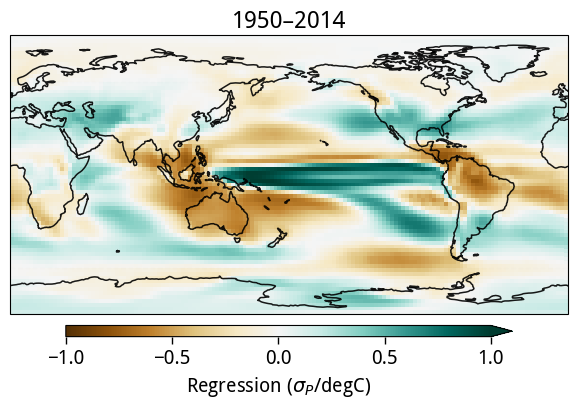

In [32]:
zz = pr_regr_smile_baseline_means.mean('smile')
sig_smiles = pr_regr_smile_baseline_pvals

plot_baseline_teleconnection(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    sig_data=sig_smiles,          # p-values (NOT binary)
    mode='smile',      # 'cmip6' or 'smile'
    p_threshold=0.05,
    agreement_threshold=0.8,
    # smile_threshold=0.25,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    vmin=-1.0,
    vmax=1.0,
    title='1950–2014',
)

plt.tight_layout()
plt.show()

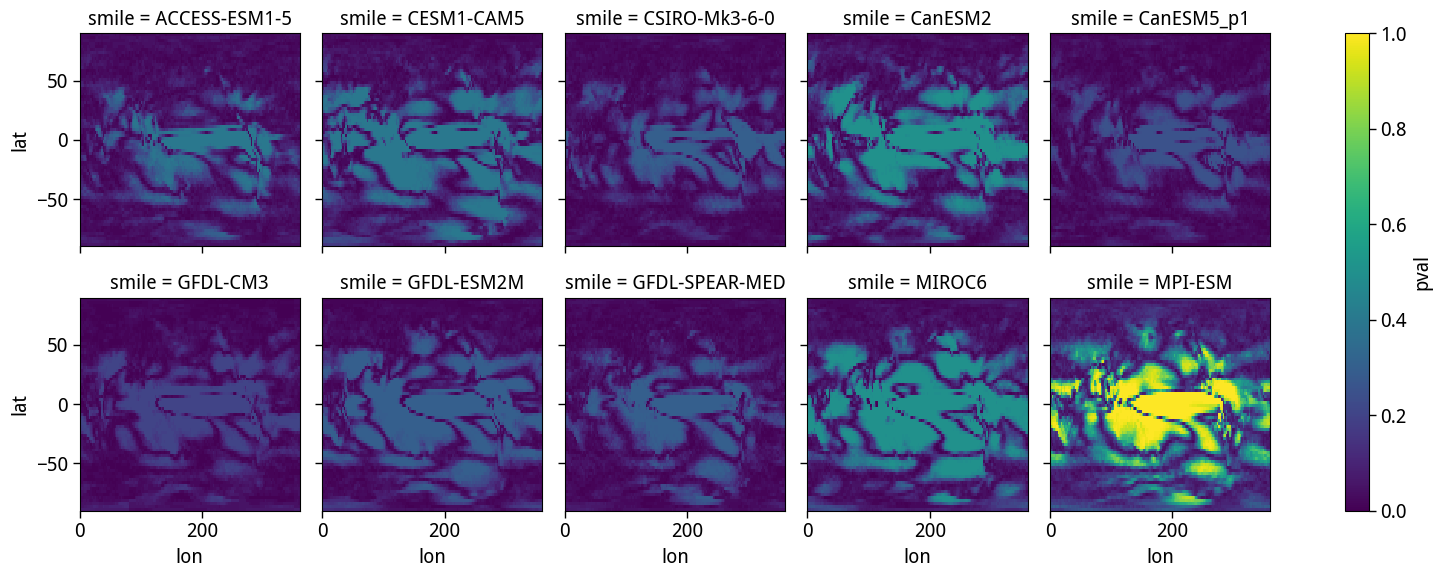

In [33]:
(pr_regr_smile_baseline_pvals <= 0.05).mean('model').plot(col='smile', col_wrap=5)

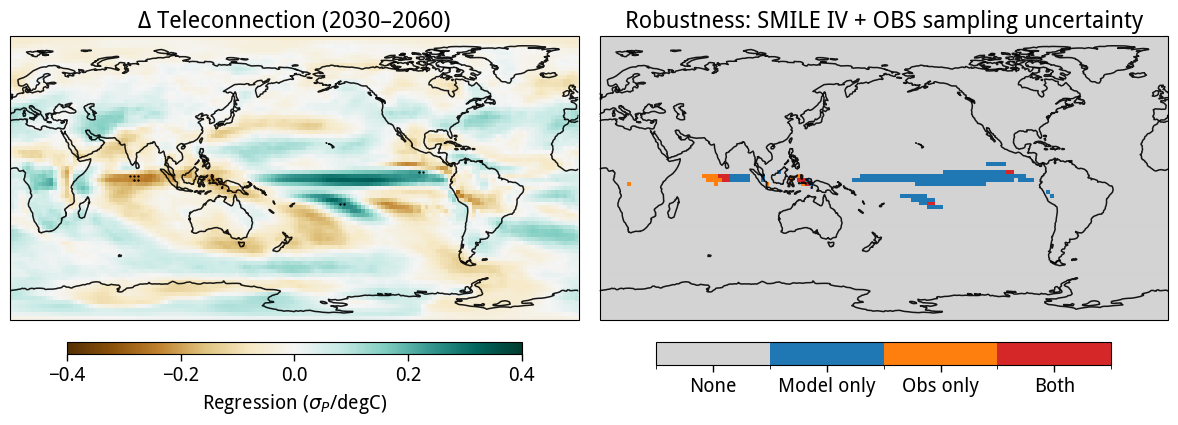

In [34]:
zz = delta_pr_regr_smile_midc_means.mean('smile')
# zp = ttest_ind3d(pr_regr_smile_baseline_means.load(), delta_pr_regr_smile_midc_means.load(), dim='smile')
zp1 = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((pr_regr_smile_baseline_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    snr_model=zp1,
    snr_obs=zp2,
    snr_threshold=1.5,
    use_pval=False,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2030–2060)',
    title_suffix = 'Robustness: SMILE IV + OBS sampling uncertainty',
)

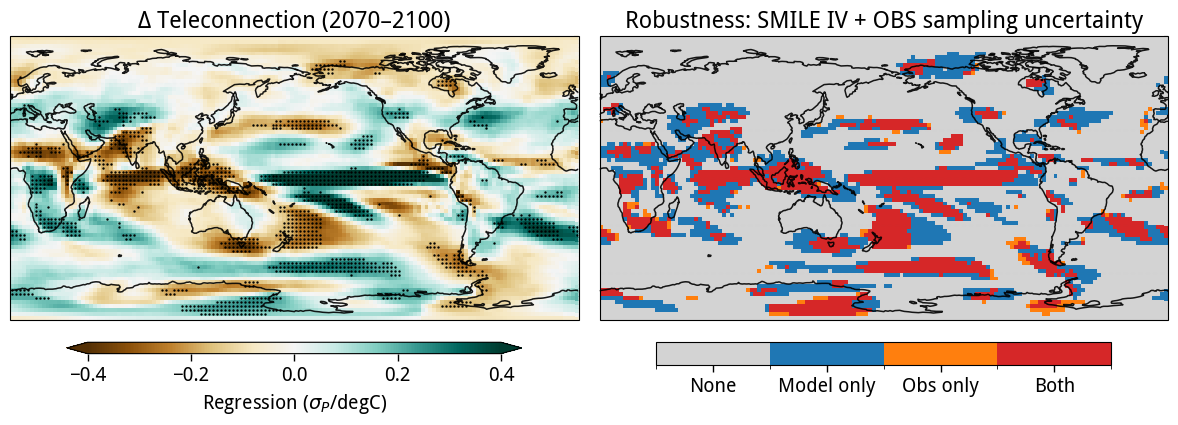

In [35]:
zz = delta_pr_regr_smile_endc_means.mean('smile')
# zp = ttest_ind3d(pr_regr_smile_baseline_means.load(), delta_pr_regr_smile_endc_means.load(), dim='smile')
zp1 = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((pr_regr_smile_baseline_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    snr_model=zp1,
    snr_obs=zp2,
    snr_threshold=1.0,
    use_pval=False,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2070–2100)',
    title_suffix = 'Robustness: SMILE IV + OBS sampling uncertainty',
)

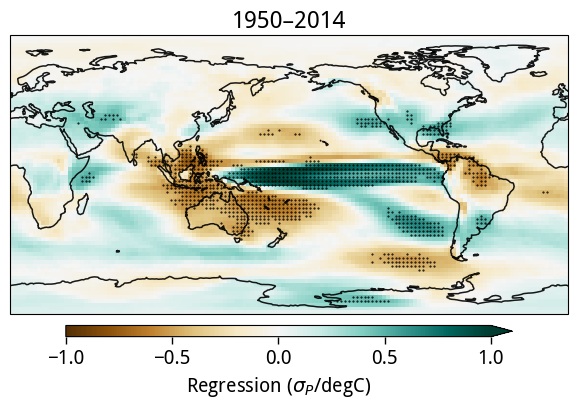

In [36]:
zz = pr_regr_cmip6_baseline.regr.mean('model')
sig_cmip6 = pr_regr_cmip6_baseline.pval

plot_baseline_teleconnection(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    sig_data=sig_cmip6,          # p-values (NOT binary)
    mode='cmip6',      # 'cmip6' or 'smile'
    p_threshold=0.05,
    agreement_threshold=0.8,
    vmin=-1.0,
    vmax=1.0,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title='1950–2014',
)

plt.tight_layout()
plt.show()

In [65]:
def ttest_ind1d(a, b):
    _, p = stats.ttest_ind(a,b, equal_var=False)
    return p


def ttest_ind3d(da1, da2, dim='model'):
    return xr.apply_ufunc(ttest_ind1d, da1, da2, input_core_dims=[[dim], [dim]], exclude_dims={dim, dim}, vectorize=True, dask='parallelized')

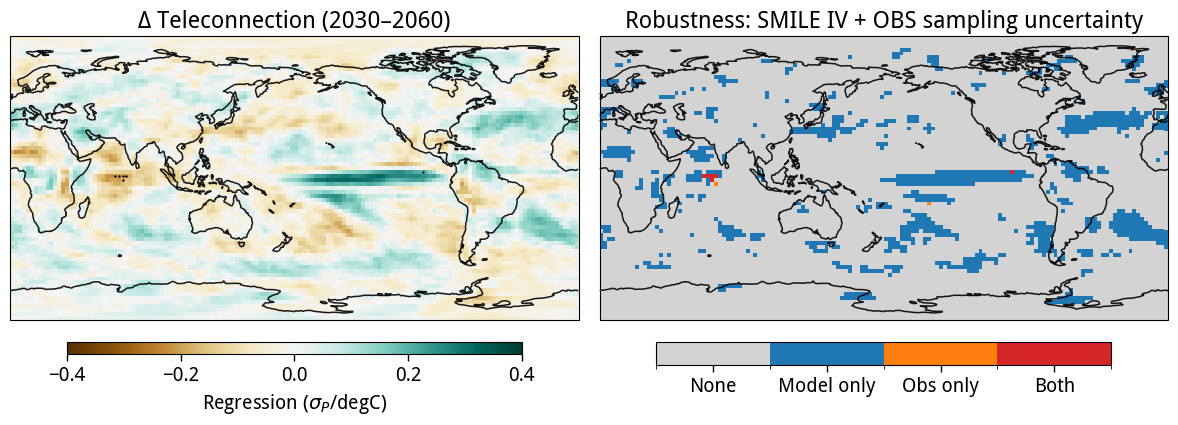

In [91]:
zz = delta_pr_regr_cmip6_midc.mean('model')
zp = ttest_ind3d(pr_regr_cmip6_baseline.regr, pr_regr_cmip6_midc.regr, dim='model')
zp1 = (np.abs(delta_pr_regr_cmip6_midc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_midc_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_cmip6_midc.mean('model'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=zp2,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2030–2060)',
    title_suffix = 'Robustness: SMILE IV + OBS sampling uncertainty',
)

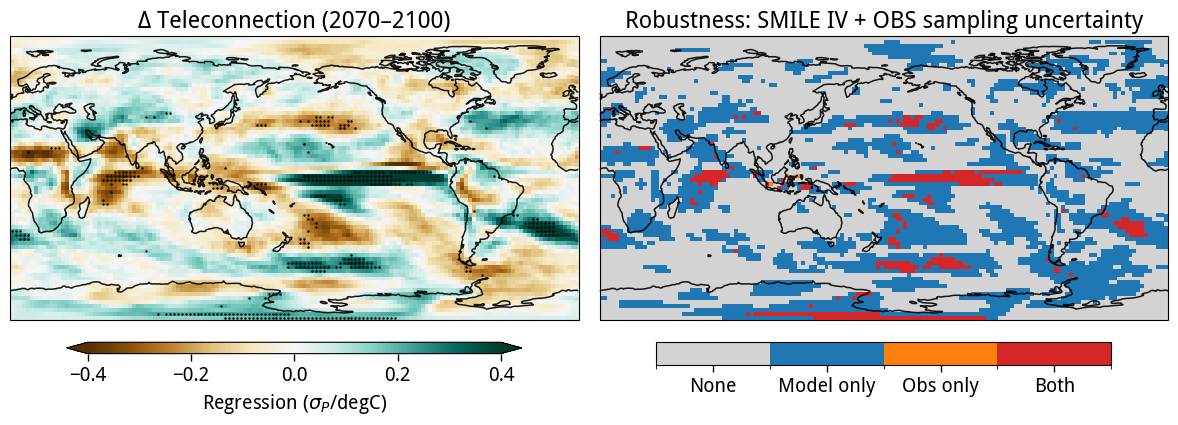

In [92]:
zz = delta_pr_regr_cmip6_endc.mean('model')
zp = ttest_ind3d(pr_regr_cmip6_baseline.regr, pr_regr_cmip6_endc.regr, dim='model')
zp1 = (np.abs(delta_pr_regr_cmip6_endc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_endc_vars).mean('smile')))
zp2 = (np.abs(delta_pr_regr_cmip6_endc.mean('model'))/np.sqrt((regridder_rean(delta_pr_regr_rean)).var('ey')))
xx, yy = np.meshgrid(zz.lon, zz.lat)


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=zp2,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2070–2100)',
    title_suffix = 'Robustness: SMILE IV + OBS sampling uncertainty',
)

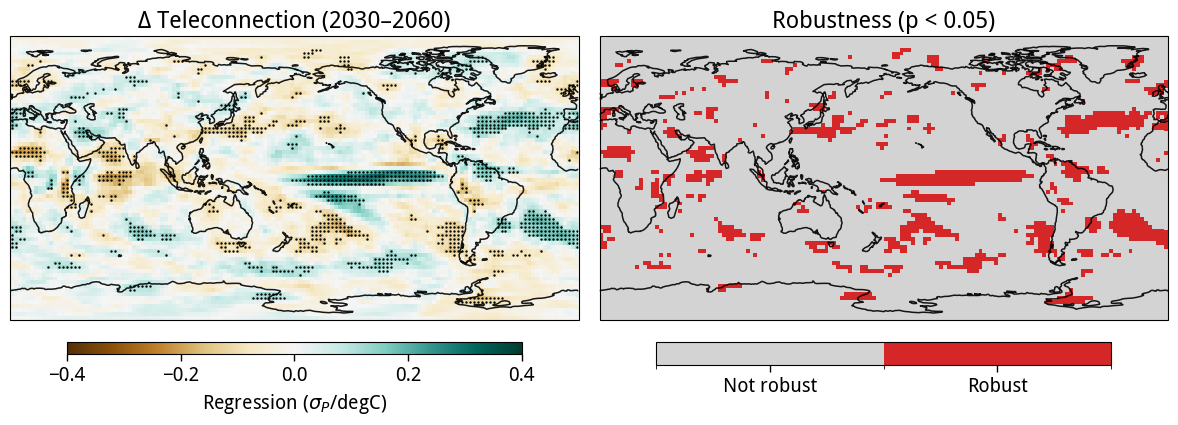

In [85]:
zz = delta_pr_regr_cmip6_midc.mean('model')
zp = ttest_ind3d(pr_regr_cmip6_baseline.regr, pr_regr_cmip6_midc.regr, dim='model')
zp1 = (np.abs(delta_pr_regr_cmip6_midc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_pr_regr_smile_midc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_midc_vars).mean('smile')))


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=None,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2030–2060)',
    title_suffix='Robustness (p < 0.05)'
)

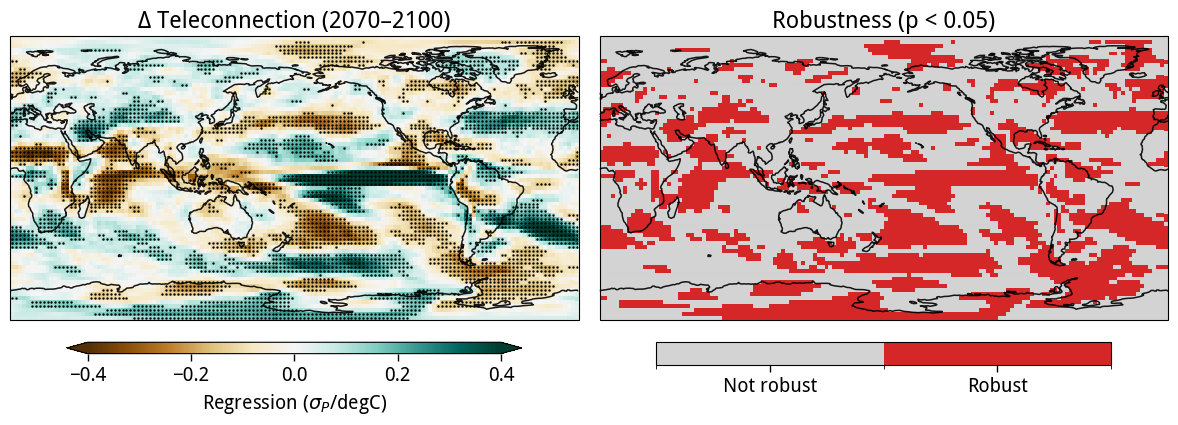

In [86]:
zz = delta_pr_regr_cmip6_endc.mean('model')
zp = ttest_ind3d(pr_regr_cmip6_baseline.regr, pr_regr_cmip6_endc.regr, dim='model')
zp1 = (np.abs(delta_pr_regr_cmip6_endc.mean('model'))/np.sqrt((pr_regr_cmip6_baseline.regr).var('model')))
# zp = (np.abs(delta_pr_regr_smile_endc_means.mean('smile'))/np.sqrt((delta_pr_regr_smile_endc_vars).mean('smile')))


plot_teleconnection_robustness(
    field=zz,
    lon=zz.lon,
    lat=zz.lat,
    pval_model=zp,
    snr_obs=None,
    pval_threshold=0.05,
    use_pval=True,
    vmin=-0.4,
    vmax=0.4,
    cmap='BrBG',
    cbar_label='Regression ($\sigma_P$/degC)',
    title_main='Δ Teleconnection (2070–2100)',
    title_suffix='Robustness (p < 0.05)'
)

In [39]:
M_baseline = pr_regr_smile_baseline_means.var('smile')
I_baseline = pr_regr_smile_baseline_vars.mean('smile')
T_baseline = M_baseline + I_baseline

In [40]:
M_midc = delta_pr_regr_smile_midc_means.var('smile')
I_midc = delta_pr_regr_smile_midc_vars.mean('smile')
T_midc = M_midc + I_midc

In [41]:
M_endc = delta_pr_regr_smile_endc_means.var('smile')
I_endc = delta_pr_regr_smile_endc_vars.mean('smile')
T_endc = M_endc + I_endc

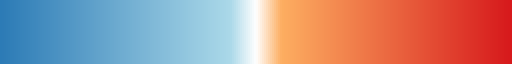

In [42]:
# Define colors
cmap = mcolors.LinearSegmentedColormap.from_list(
    "model_vs_internal",
    [
        (0.0, "#2c7bb6"),   # blue (internal variability dominates)
        (0.45, "#abd9e9"),  # light blue
        (0.50, "#ffffff"),  # neutral
        (0.55, "#fdae61"),  # light orange
        (1.0, "#d7191c"),   # red (model dominates)
    ]
)
cmap

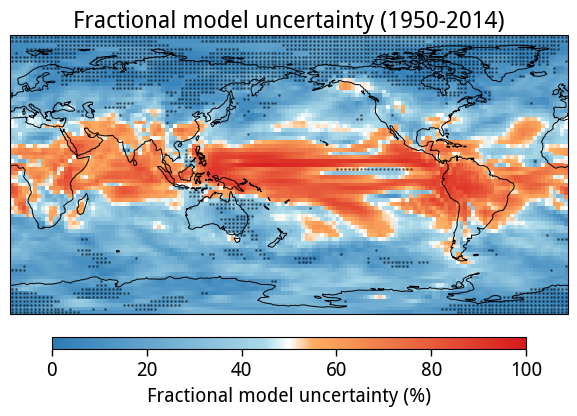

In [43]:
zz = (M_baseline / (M_baseline + I_baseline + 1e-12)) * 100

xx, yy = np.meshgrid(zz.lon, zz.lat)

T_baseline = M_baseline + I_baseline

fig = plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

# ---------------------------
# Plot main field
# ---------------------------
im = zz.plot(
    ax=ax,
    vmin=0,
    vmax=100,
    cmap=cmap,
    transform=ccrs.PlateCarree(),
    cbar_kwargs=dict(
        orientation='horizontal',
        shrink=0.85,
        aspect=40,
        pad=0.05,
        label='Fractional model uncertainty (%)'
    )
)

# ---------------------------
# Stippling: low total uncertainty regions
# ---------------------------
low_unc = T_baseline < np.nanpercentile(T_baseline, 20)

ax.scatter(
    xx[low_unc],
    yy[low_unc],
    s=1,
    color='k',
    alpha=0.4,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# ---------------------------
# Map aesthetics
# ---------------------------
ax.coastlines(linewidth=0.7)
ax.set_global()
ax.set_title('Fractional model uncertainty (1950-2014)')

plt.tight_layout()
plt.show()



# NOTE -  Stippling indicates regions where total uncertainty (M + I) lies in the lowest quintile of the domain distribution, representing areas where fractional partitioning is less informative due to weak overall uncertainty magnitude

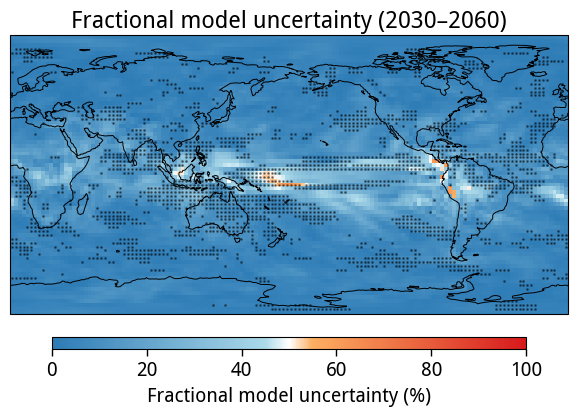

In [44]:
zz = (M_midc / (M_midc + I_midc + 1e-12)) * 100

xx, yy = np.meshgrid(zz.lon, zz.lat)

T_midc = M_midc + I_midc

fig = plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

# ---------------------------
# Plot main field
# ---------------------------
im = zz.plot(
    ax=ax,
    vmin=0,
    vmax=100,
    cmap=cmap,
    transform=ccrs.PlateCarree(),
    cbar_kwargs=dict(
        orientation='horizontal',
        shrink=0.85,
        aspect=40,
        pad=0.05,
        label='Fractional model uncertainty (%)'
    )
)

# ---------------------------
# Stippling: low total uncertainty regions
# ---------------------------
low_unc = T_midc < np.nanpercentile(T_midc, 20)

ax.scatter(
    xx[low_unc],
    yy[low_unc],
    s=1,
    color='k',
    alpha=0.4,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# ---------------------------
# Map aesthetics
# ---------------------------
ax.coastlines(linewidth=0.7)
ax.set_global()
ax.set_title('Fractional model uncertainty (2030–2060)')

plt.tight_layout()
plt.show()



# NOTE -  Stippling indicates regions where total uncertainty (M + I) lies in the lowest quintile of the domain distribution, representing areas where fractional partitioning is less informative due to weak overall uncertainty magnitude

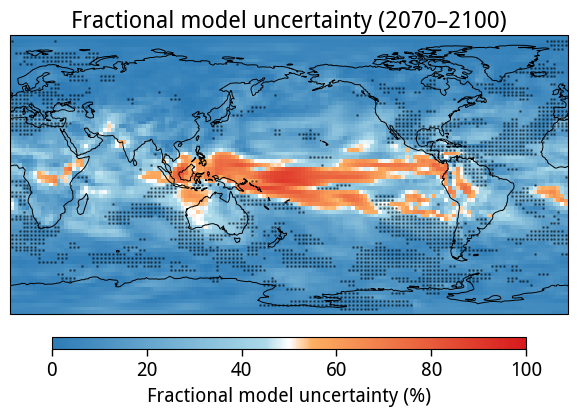

In [45]:
zz = (M_endc / (M_endc + I_endc + 1e-12)) * 100

xx, yy = np.meshgrid(zz.lon, zz.lat)

T_endc = M_endc + I_endc

fig = plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))

# ---------------------------
# Plot main field
# ---------------------------
im = zz.plot(
    ax=ax,
    vmin=0,
    vmax=100,
    cmap=cmap,
    transform=ccrs.PlateCarree(),
    cbar_kwargs=dict(
        orientation='horizontal',
        shrink=0.85,
        aspect=40,
        pad=0.05,
        label='Fractional model uncertainty (%)'
    )
)

# ---------------------------
# Stippling: low total uncertainty regions
# ---------------------------
low_unc = T_endc < np.nanpercentile(T_endc, 20)

ax.scatter(
    xx[low_unc],
    yy[low_unc],
    s=1,
    color='k',
    alpha=0.4,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# ---------------------------
# Map aesthetics
# ---------------------------
ax.coastlines(linewidth=0.7)
ax.set_global()
ax.set_title('Fractional model uncertainty (2070–2100)')

plt.tight_layout()
plt.show()



# NOTE -  Stippling indicates regions where total uncertainty (M + I) lies in the lowest quintile of the domain distribution, representing areas where fractional partitioning is less informative due to weak overall uncertainty magnitude

In [46]:
plot_list = [
    (T_baseline) - ts_regr_cmip6_baseline.regr.var('model'),
    (T_midc) - ts_regr_cmip6_midc.regr.var('model'),
    (T_endc) - ts_regr_cmip6_endc.regr.var('model'),
]

titles_list = [
    'Baseline',
    'Mid century',
    'End century',
]

labels_list = [
    'a',
    'b',
    'c',
]

In [47]:
# ### Fractional model uncertainty in Base period and in mid century changes and end century changes

# xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)
# plot_maps(xx, yy, plot_list, titles_list, labels_list, cmap='bwr', levels=np.linspace(-0.1, 0.1, 21), pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
#             nrows=1, ncols=3, figsize=(20,8), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.PlateCarree(central_longitude=180), 
#             cbar_kwargs=dict(orientation='horizontal', label='Relative uncertainty', aspect=45, shrink=0.5, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

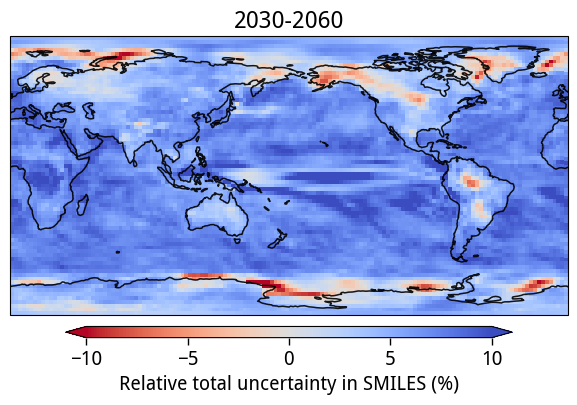

In [48]:
zz = ((T_midc) - ts_regr_cmip6_midc.regr.var('model'))*100

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -10, vmax=10, cmap='coolwarm_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Relative total uncertainty in SMILES (%)'), transform=ccrs.PlateCarree())


ax.set_title('2030-2060')
plot_background(ax)
plt.tight_layout()



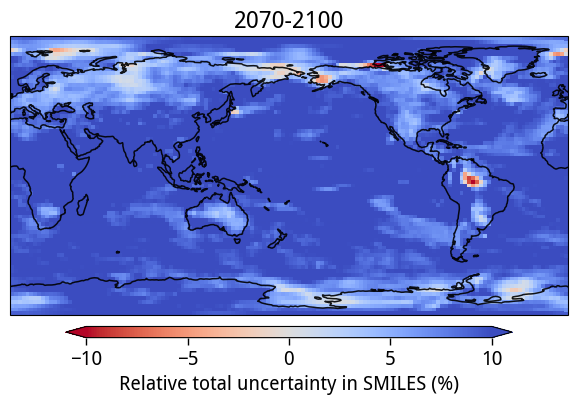

In [49]:
zz = ((T_endc) - ts_regr_cmip6_endc.regr.var('model'))*100

plt.figure(figsize=(6,5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
zz.plot(vmin = -10, vmax=10, cmap='coolwarm_r', cbar_kwargs=dict(orientation='horizontal', shrink=0.8, aspect=40, pad=0.025, label = 'Relative total uncertainty in SMILES (%)'), transform=ccrs.PlateCarree())


ax.set_title('2070-2100')
plot_background(ax)
plt.tight_layout()



### composite changes

In [20]:
base_path = "/g/data/if69/as8561/data/enso_tele_robustness"

smile_models = [
    'ACCESS-ESM1-5',
    'CESM1-CAM5',
    'CSIRO-Mk3-6-0',
    'CanESM2',
    'CanESM5_p1',
    'GFDL-CM3',
    'GFDL-ESM2M',
    'GFDL-SPEAR-MED',
    'MIROC6',
    'MPI-ESM',
]


In [21]:
from tqdm.auto import tqdm

In [22]:
clim_base = slice('1960', '1990')
baseline  = slice('1950', '2014')

In [23]:
# Load
tas_obs  = xr.open_dataset(f"{base_path}/tas_obs.nc").load()
pr_obs   = xr.open_dataset(f"{base_path}/pr_obs.nc").load()
pr_rean  = xr.open_dataset(f"{base_path}/pr_rean.nc").load()
nino34   = xr.open_dataset(f"{base_path}/nino34_index_hadisst.nc").load()
tas_cmip6 = xr.open_dataset(f"{base_path}/cmip6/ts_ssp5.nc").load()
pr_cmip6  = xr.open_dataset(f"{base_path}/cmip6/pr_ssp5.nc").load()

# Detrend obs/rean/cmip6 — already anomalised
tas_obs['ts']  = funcs.detrend_rolling_window(tas_obs['tas'],  window_size=15)
pr_obs['pr']    = funcs.detrend_rolling_window(pr_obs['pr'],    window_size=15)
pr_rean['pr']   = funcs.detrend_rolling_window(pr_rean['pr'],   window_size=15)
tas_cmip6['ts'] = funcs.detrend_rolling_window(tas_cmip6['ts'], window_size=15)
pr_cmip6['pr']  = funcs.detrend_rolling_window(pr_cmip6['pr'],  window_size=15)

# Standardise PR — per gridpoint std over full record
pr_obs['pr']   = pr_obs['pr']   / pr_obs['pr'].std('time')
pr_rean['pr']  = pr_rean['pr']  / pr_rean['pr'].std('time')
pr_cmip6['pr'] = pr_cmip6['pr'] / pr_cmip6['pr'].std('time')

# Detrend nino34 obs
nino34_obs = nino34.rename({'tos': 'ts'})
nino34_obs['ts'] = funcs.detrend_rolling_window(nino34_obs['ts'], window_size=15)

In [25]:
tas_smile, pr_smile, nino34_smile = {}, {}, {}

nino34_lat = slice(-5, 5)
nino34_lon = slice(190, 240)

for m in tqdm(smile_models, desc='Loading and processing SMILEs'):
    # Load
    ts = xr.open_dataset(f"{base_path}/smiles/{m}_ts.nc", decode_times=False)
    pr = xr.open_dataset(f"{base_path}/smiles/{m}_pr.nc", decode_times=False)
    ts = xr.decode_cf(ts).convert_calendar('standard', use_cftime=False).load()
    pr = xr.decode_cf(pr).convert_calendar('standard', use_cftime=False).load()

    # Rename tas to ts
    ts = ts.rename({list(ts.data_vars)[0]: 'ts'})
    pr = pr.rename({list(pr.data_vars)[0]: 'pr'})

    # Anomaly + detrend
    ts['ts'] = funcs.detrend_rolling_window(
        funcs.calc_anom_annual(ts['ts'], ts['ts'].sel(time=clim_base)),
        window_size=15
    )
    pr['pr'] = funcs.detrend_rolling_window(
        funcs.calc_anom_annual(pr['pr'], pr['pr'].sel(time=clim_base)),
        window_size=15
    )

    # Standardise PR
    pr['pr'] = pr['pr'] / pr['pr'].std('time')

    # Nino3.4 index
    nino34_smile[m] = ts['ts'].sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])

    tas_smile[m] = ts
    pr_smile[m]  = pr

Loading and processing SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

: 

In [24]:
import xesmf as xe

# --- Build regridders once using full fields as template ---
regridder_pr_rean = xe.Regridder(pr_rean,  tas_obs, 'bilinear',
                                  periodic=True, ignore_degenerate=True)
# regridder_tas_obs = xe.Regridder(tas_obs,  tas_cmip6, 'bilinear',
#                                   periodic=True, ignore_degenerate=True)
# regridder_pr_obs  = xe.Regridder(pr_obs,   tas_cmip6, 'bilinear',
#                                   periodic=True, ignore_degenerate=True)

# # --- Regrid ---
pr_rean_regrid = regridder_pr_rean(pr_rean['pr'])
# tas_obs_regrid = regridder_tas_obs(tas_obs['tas'])
# pr_obs_regrid  = regridder_pr_obs(pr_obs['pr'])

# Regrid CMIP6 to SMILE grid
regridder_cmip6_to_smile = xe.Regridder(
    tas_cmip6, tas_smile['ACCESS-ESM1-5'],
    'bilinear', periodic=True, ignore_degenerate=True
)

tas_cmip6_regrid = regridder_cmip6_to_smile(tas_cmip6['ts'])
pr_cmip6_regrid  = regridder_cmip6_to_smile(pr_cmip6['pr'])
nino34_cmip6     = tas_cmip6_regrid.sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])

NameError: name 'tas_smile' is not defined

In [ ]:
pr_rean_regrid

<xarray.DataArray (time: 181, lat: 72, lon: 144)> Size: 8MB
array([[[ 0.3598478 ,  0.34797767,  0.34928456, ...,  0.37918818,
          0.38093185,  0.36273336],
        [ 0.37898543,  0.39309812,  0.41411024, ...,  0.3535402 ,
          0.3612698 ,  0.3847404 ],
        [ 0.34550008,  0.3558439 ,  0.35201535, ...,  0.2954949 ,
          0.32829264,  0.3409277 ],
        ...,
        [-0.40988255, -0.41222587, -0.4240365 , ..., -0.3798572 ,
         -0.39730898, -0.4064333 ],
        [-0.388088  , -0.39358154, -0.3911582 , ..., -0.3787509 ,
         -0.38313353, -0.3853692 ],
        [-0.22181426, -0.2213839 , -0.22094682, ..., -0.22235416,
         -0.22337967, -0.22152917]],

       [[-0.56796396, -0.5431723 , -0.5554851 , ..., -0.56339395,
         -0.5753078 , -0.56396216],
        [-0.5931369 , -0.58673704, -0.5907908 , ..., -0.5399094 ,
         -0.5640921 , -0.59048104],
        [-0.37084562, -0.36873198, -0.36960927, ..., -0.39381406,
         -0.41119027, -0.39075944],
...
        [ 1.3625195 ,  1.1929013 ,  1.0756799 , ...,  1.8504353 ,
          1.7269614 ,  1.5329543 ],
        [ 1.3530098 ,  1.2958316 ,  1.2485662 , ...,  1.6400398 ,
          1.5386264 ,  1.4314213 ],
        [ 2.8510206 ,  2.8559937 ,  2.8578763 , ...,  2.8208582 ,
          2.832551  ,  2.845463  ]],

       [[ 0.17249925,  0.16008304,  0.14311084, ...,  0.19201376,
          0.18524432,  0.18453076],
        [ 1.1721916 ,  1.1426617 ,  1.1032087 , ...,  1.2093097 ,
          1.1942762 ,  1.1888198 ],
        [ 1.5965018 ,  1.5576457 ,  1.505671  , ...,  1.6254972 ,
          1.609916  ,  1.601075  ],
        ...,
        [ 0.39486834,  0.44444633,  0.47263065, ...,  0.00663859,
          0.18204962,  0.30779436],
        [ 0.08290421,  0.11693346,  0.15213625, ..., -0.11007354,
         -0.04333578,  0.03079221],
        [-1.335353  , -1.3357791 , -1.3382668 , ..., -1.3281664 ,
         -1.3281779 , -1.3320404 ]]], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 1kB 1835-06-01 1836-06-01 ... 2015-06-01
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * lat      (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
Attributes:
    regrid_method:  bilinear

In [ ]:
nino34_cmip6 = tas_cmip6['ts'].sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])

# Thresholds from baseline
obs_std   = float(nino34_obs['ts'].sel(time=baseline).std('time'))
cmip6_std = nino34_cmip6.sel(time=baseline).std('time')   # (model,)

# Obs masks
cond_en_obs  = nino34_obs['ts'] >  0.5 * obs_std
cond_ln_obs  = nino34_obs['ts'] < -0.5 * obs_std
cond_neu_obs = (nino34_obs['ts'] >= -0.25 * obs_std) & \
               (nino34_obs['ts'] <= 0.25 * obs_std)

# CMIP6 masks — per model
cond_en_cmip6  = nino34_cmip6 >  0.5 * cmip6_std
cond_ln_cmip6  = nino34_cmip6 < -0.5 * cmip6_std
cond_neu_cmip6 = (nino34_cmip6 >= -0.25 * cmip6_std) & \
                 (nino34_cmip6 <=  0.25 * cmip6_std)

# SMILE masks — per member
cond_en_smile, cond_ln_smile, cond_neu_smile = {}, {}, {}
for m in smile_models:
    smile_std         = nino34_smile[m].sel(time=baseline).std('time')
    cond_en_smile[m]  = nino34_smile[m] >  0.5 * smile_std
    cond_ln_smile[m]  = nino34_smile[m] < -0.5 * smile_std
    cond_neu_smile[m] = (nino34_smile[m] >= -0.25 * smile_std) & \
                        (nino34_smile[m] <=  0.25 * smile_std)

print(f"Obs EN years:  {int(cond_en_obs.sum())}")
print(f"Obs LN years:  {int(cond_ln_obs.sum())}")
print(f"CMIP6 EN per model (mean): {float(cond_en_cmip6.sum('time').mean()):.1f}")

Obs EN years:  32
Obs LN years:  35
CMIP6 EN per model (mean): 77.4


In [ ]:
def make_composites(da, cond_en, cond_ln, cond_neu):
    """
    Returns EN, LN, NEU composite means.
    Handles NaN years cleanly.
    """
    en  = da.where(cond_en).mean( 'time', skipna=True)
    ln  = da.where(cond_ln).mean( 'time', skipna=True)
    neu = da.where(cond_neu).mean('time', skipna=True)
    return en, ln, neu

# Obs baseline composites — on CMIP6 grid now
tas_en_obs, tas_ln_obs, tas_neu_obs = make_composites(
    tas_obs.sel(time=baseline),
    cond_en_obs.sel(time=baseline),
    cond_ln_obs.sel(time=baseline),
    cond_neu_obs.sel(time=baseline)
)
pr_en_rean, pr_ln_rean, pr_neu_rean = make_composites(
    pr_rean_regrid.sel(time=baseline),
    cond_en_obs.sel(time=baseline),
    cond_ln_obs.sel(time=baseline),
    cond_neu_obs.sel(time=baseline)
)

# CMIP6 baseline composites
tas_en_cmip6_base, tas_ln_cmip6_base, tas_neu_cmip6_base = make_composites(
    tas_cmip6_regrid.sel(time=baseline),
    cond_en_cmip6.sel(time=baseline),
    cond_ln_cmip6.sel(time=baseline),
    cond_neu_cmip6.sel(time=baseline)
)
pr_en_cmip6_base, pr_ln_cmip6_base, pr_neu_cmip6_base = make_composites(
    pr_cmip6_regrid.sel(time=baseline),
    cond_en_cmip6.sel(time=baseline),
    cond_ln_cmip6.sel(time=baseline),
    cond_neu_cmip6.sel(time=baseline)
)

In [ ]:
# # --- Obs MW test ---
# pval_en_obs_tas = funcs.mannwhitneyu3d(
#     tas_obs.sel(time=baseline).where(cond_en_obs.sel(time=baseline),  drop=True),
#     tas_obs.sel(time=baseline).where(cond_neu_obs.sel(time=baseline), drop=True),
#     dim='time'
# )
# print('done')
# pval_ln_obs_tas = funcs.mannwhitneyu3d(
#     tas_obs.sel(time=baseline).where(cond_ln_obs.sel(time=baseline),  drop=True),
#     tas_obs.sel(time=baseline).where(cond_neu_obs.sel(time=baseline), drop=True),
#     dim='time'
# )
# print('done')
# pval_en_obs_pr = funcs.mannwhitneyu3d(
#     pr_rean.sel(time=baseline).where(cond_en_obs.sel(time=baseline),  drop=True),
#     pr_rean.sel(time=baseline).where(cond_neu_obs.sel(time=baseline), drop=True),
#     dim='time'
# )
# print('done')
# pval_ln_obs_pr = funcs.mannwhitneyu3d(
#     pr_rean.sel(time=baseline).where(cond_ln_obs.sel(time=baseline),  drop=True),
#     pr_rean.sel(time=baseline).where(cond_neu_obs.sel(time=baseline), drop=True),
#     dim='time'
# )
# print('done')

# # --- CMIP6 MW test — per model ---
# pval_en_cmip6_tas = funcs.mannwhitneyu3d(
#     tas_cmip6['ts'].sel(time=baseline).where(cond_en_cmip6.sel(time=baseline)),
#     tas_cmip6['ts'].sel(time=baseline).where(cond_neu_cmip6.sel(time=baseline)),
#     dim='time'
# )
# pval_ln_cmip6_tas = funcs.mannwhitneyu3d(
#     tas_cmip6['ts'].sel(time=baseline).where(cond_ln_cmip6.sel(time=baseline)),
#     tas_cmip6['ts'].sel(time=baseline).where(cond_neu_cmip6.sel(time=baseline)),
#     dim='time'
# )
# pval_en_cmip6_pr = funcs.mannwhitneyu3d(
#     pr_cmip6['pr'].sel(time=baseline).where(cond_en_cmip6.sel(time=baseline)),
#     pr_cmip6['pr'].sel(time=baseline).where(cond_neu_cmip6.sel(time=baseline)),
#     dim='time'
# )
# pval_ln_cmip6_pr = funcs.mannwhitneyu3d(
#     pr_cmip6['pr'].sel(time=baseline).where(cond_ln_cmip6.sel(time=baseline)),
#     pr_cmip6['pr'].sel(time=baseline).where(cond_neu_cmip6.sel(time=baseline)),
#     dim='time'
# )

In [ ]:
def plot_composite(field, lon, lat, vmin=-1.0, vmax=1.0,
                   cmap='RdBu_r', cbar_label='', title=''):
    fig = plt.figure(figsize=(8, 4))
    ax  = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
    
    field.plot(
        ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
        cbar_kwargs=dict(orientation='horizontal', shrink=0.6,
                         aspect=40, pad=0.05, label=cbar_label),
        transform=ccrs.PlateCarree()
    )
    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()

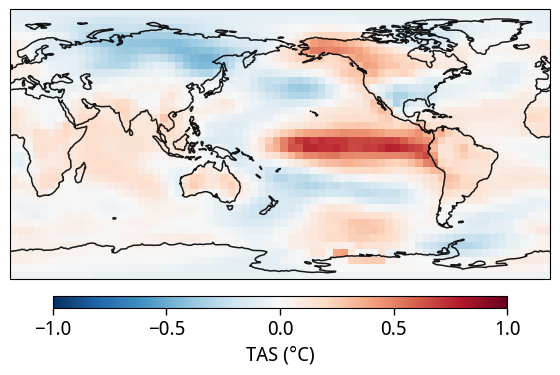

In [ ]:
# obs MMM baseline composites
plot_composite(tas_en_obs.ts, 
               tas_obs.lon.values, tas_obs.lat.values,
               cmap='RdBu_r', cbar_label='TAS (°C)', vmin=-1,
               title='')


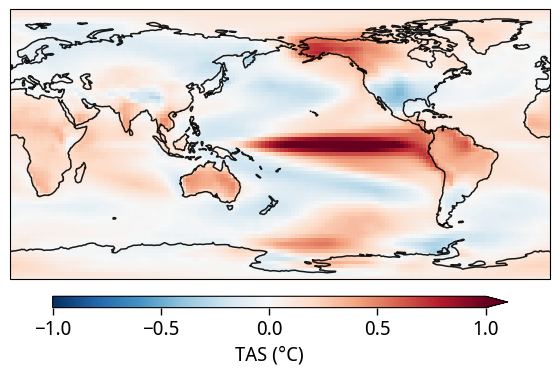

In [ ]:
# CMIP6 MMM baseline composites
plot_composite(tas_en_cmip6_base.mean('model'), 
               tas_cmip6.lon.values, tas_cmip6.lat.values,
               cmap='RdBu_r', cbar_label='TAS (°C)',
               title='')


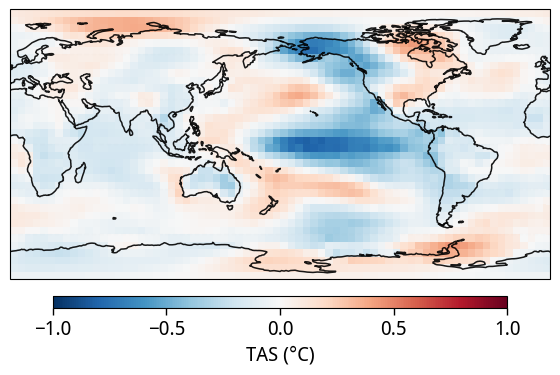

In [ ]:
# obs MMM baseline composites
plot_composite(tas_ln_obs.ts, 
               tas_obs.lon.values, tas_obs.lat.values,
               cmap='RdBu_r', cbar_label='TAS (°C)',
               title='')


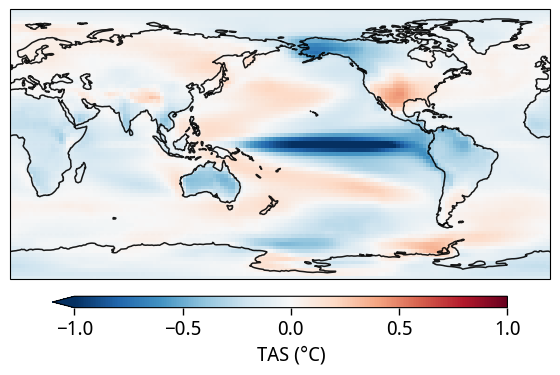

In [ ]:
plot_composite(tas_ln_cmip6_base.mean('model'),
               tas_cmip6.lon.values, tas_cmip6.lat.values,
               cmap='RdBu_r', cbar_label='TAS (°C)',
               title='')


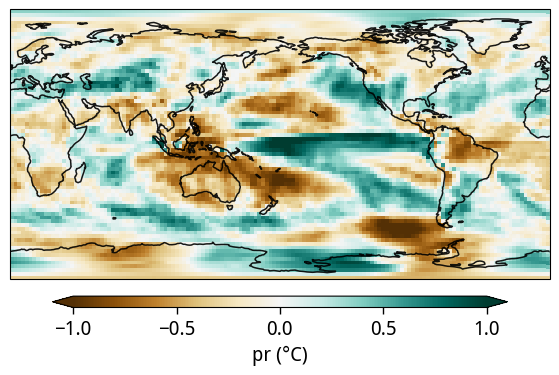

In [ ]:
# rean MMM baseline composites
plot_composite(pr_en_rean, 
               pr_rean.lon.values, pr_rean.lat.values,
               cmap='BrBG', cbar_label='pr (°C)', vmin=-1,
               title='')


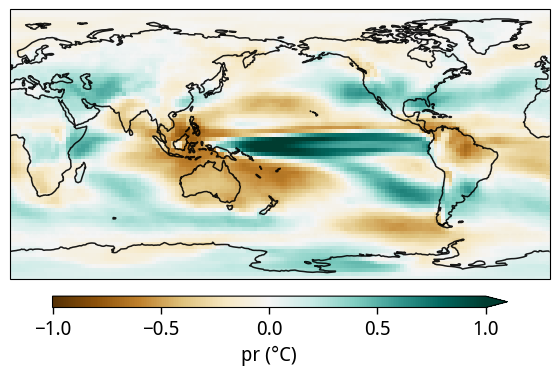

In [ ]:
# CMIP6 MMM baseline composites
plot_composite(pr_en_cmip6_base.mean('model'), 
               pr_cmip6.lon.values, pr_cmip6.lat.values,
               cmap='BrBG', cbar_label='pr (°C)',
               title='')


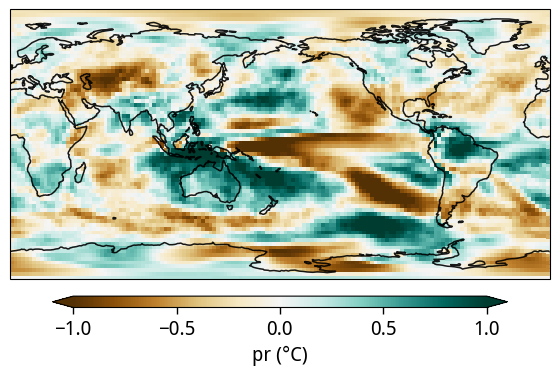

In [ ]:
# rean MMM baseline composites
plot_composite(pr_ln_rean, 
               pr_rean.lon.values, pr_rean.lat.values,
               cmap='BrBG', cbar_label='pr (°C)',
               title='')


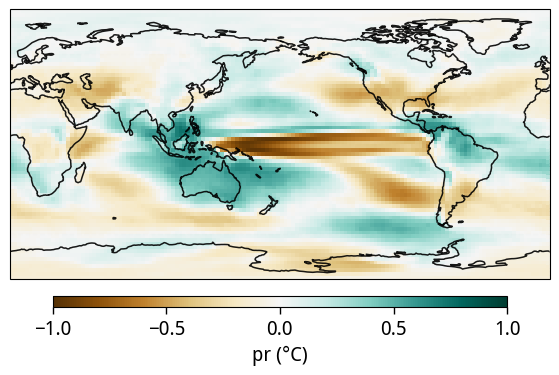

In [ ]:
plot_composite(pr_ln_cmip6_base.mean('model'),
               pr_cmip6.lon.values, pr_cmip6.lat.values,
               cmap='BrBG', cbar_label='pr (°C)',
               title='')


In [ ]:
fut = slice('2070', '2100')

# --- CMIP6 future composites ---
tas_en_cmip6_fut, tas_ln_cmip6_fut, _ = make_composites(
    tas_cmip6_regrid.sel(time=fut),
    cond_en_cmip6.sel(time=fut),
    cond_ln_cmip6.sel(time=fut),
    cond_neu_cmip6.sel(time=fut)
)
pr_en_cmip6_fut, pr_ln_cmip6_fut, _ = make_composites(
    pr_cmip6_regrid.sel(time=fut),
    cond_en_cmip6.sel(time=fut),
    cond_ln_cmip6.sel(time=fut),
    cond_neu_cmip6.sel(time=fut)
)

# --- Signal = future minus baseline MMM ---
signal_en_tas = (tas_en_cmip6_fut - tas_en_cmip6_base).mean('model')
signal_ln_tas = (tas_ln_cmip6_fut - tas_ln_cmip6_base).mean('model')
signal_en_pr  = (pr_en_cmip6_fut  - pr_en_cmip6_base).mean('model')
signal_ln_pr  = (pr_ln_cmip6_fut  - pr_ln_cmip6_base).mean('model')

In [ ]:
pval_en_tas_ttest = ttest_ind3d(tas_en_cmip6_fut, tas_en_cmip6_base, dim='model')
pval_ln_tas_ttest = ttest_ind3d(tas_ln_cmip6_fut, tas_ln_cmip6_base, dim='model')
pval_en_pr_ttest  = ttest_ind3d(pr_en_cmip6_fut,  pr_en_cmip6_base,  dim='model')
pval_ln_pr_ttest  = ttest_ind3d(pr_ln_cmip6_fut,  pr_ln_cmip6_base,  dim='model')

In [ ]:
# --- Obs rolling 30-year composite std as noise ---
def obs_rolling_std(da, cond_en, cond_ln,
                    start=1900, end=2014, duration=30, gap=1):
    en_means, ln_means = [], []
    for yr in range(start, end - duration + 2, gap):
        win    = slice(str(yr), str(yr + duration - 1))
        en_sub = da.sel(time=win).where(cond_en.sel(time=win), drop=True)
        ln_sub = da.sel(time=win).where(cond_ln.sel(time=win), drop=True)
        if en_sub.sizes['time'] > 2:
            en_means.append(en_sub.mean('time', skipna=True))
        if ln_sub.sizes['time'] > 2:
            ln_means.append(ln_sub.mean('time', skipna=True))
    en_std = xr.concat(en_means, dim='window').std('window')
    ln_std = xr.concat(ln_means, dim='window').std('window')
    return en_std, ln_std

print("Computing obs rolling std for TAS...")
noise_en_tas_obs, noise_ln_tas_obs = obs_rolling_std(
    tas_obs.ts, cond_en_obs, cond_ln_obs)

print("Computing obs rolling std for PR...")
noise_en_pr_obs, noise_ln_pr_obs = obs_rolling_std(
    pr_rean_regrid, cond_en_obs, cond_ln_obs)

Computing obs rolling std for TAS...
Computing obs rolling std for PR...


In [ ]:
# --- SMILE IV ---
en_iv_tas_list, ln_iv_tas_list = [], []
en_iv_pr_list,  ln_iv_pr_list  = [], []

for m in tqdm(smile_models, desc='SMILE IV'):
    en_base_sm, ln_base_sm, _ = make_composites(
        tas_smile[m]['ts'].sel(time=baseline),
        cond_en_smile[m].sel(time=baseline),
        cond_ln_smile[m].sel(time=baseline),
        cond_neu_smile[m].sel(time=baseline)
    )
    en_iv_tas_list.append(en_base_sm.std('model'))
    ln_iv_tas_list.append(ln_base_sm.std('model'))

    en_base_pr, ln_base_pr, _ = make_composites(
        pr_smile[m]['pr'].sel(time=baseline),
        cond_en_smile[m].sel(time=baseline),
        cond_ln_smile[m].sel(time=baseline),
        cond_neu_smile[m].sel(time=baseline)
    )
    en_iv_pr_list.append(en_base_pr.std('model'))
    ln_iv_pr_list.append(ln_base_pr.std('model'))

# Average IV across SMILE models
iv_en_tas = xr.concat(en_iv_tas_list, dim='smile', coords='minimal').mean('smile')
iv_ln_tas = xr.concat(ln_iv_tas_list, dim='smile', coords='minimal').mean('smile')
iv_en_pr  = xr.concat(en_iv_pr_list,  dim='smile', coords='minimal').mean('smile')
iv_ln_pr  = xr.concat(ln_iv_pr_list,  dim='smile', coords='minimal').mean('smile')

SMILE IV:   0%|          | 0/10 [00:00<?, ?it/s]

In [ ]:
# --- SNR ---
snr_en_tas_obs = signal_en_tas / noise_en_tas_obs
snr_ln_tas_obs = signal_ln_tas / noise_ln_tas_obs
snr_en_pr_obs  = signal_en_pr.drop('height')  / noise_en_pr_obs
snr_ln_pr_obs  = signal_ln_pr.drop('height')  / noise_ln_pr_obs

snr_en_tas_iv  = signal_en_tas / iv_en_tas
snr_ln_tas_iv  = signal_ln_tas / iv_ln_tas
snr_en_pr_iv   = signal_en_pr  / iv_en_pr
snr_ln_pr_iv   = signal_ln_pr  / iv_ln_pr

# --- Masks ---
threshold = 1.5

mask_en_tas_ttest = pval_en_tas_ttest < 0.05
mask_ln_tas_ttest = pval_ln_tas_ttest < 0.05
mask_en_pr_ttest  = pval_en_pr_ttest  < 0.05
mask_ln_pr_ttest  = pval_ln_pr_ttest  < 0.05

mask_en_tas_obs   = snr_en_tas_obs > threshold
mask_ln_tas_obs   = snr_ln_tas_obs > threshold
mask_en_pr_obs    = snr_en_pr_obs  > threshold
mask_ln_pr_obs    = snr_ln_pr_obs  > threshold

mask_en_tas_iv    = snr_en_tas_iv  > threshold
mask_ln_tas_iv    = snr_ln_tas_iv  > threshold
mask_en_pr_iv     = snr_en_pr_iv   > threshold
mask_ln_pr_iv     = snr_ln_pr_iv   > threshold

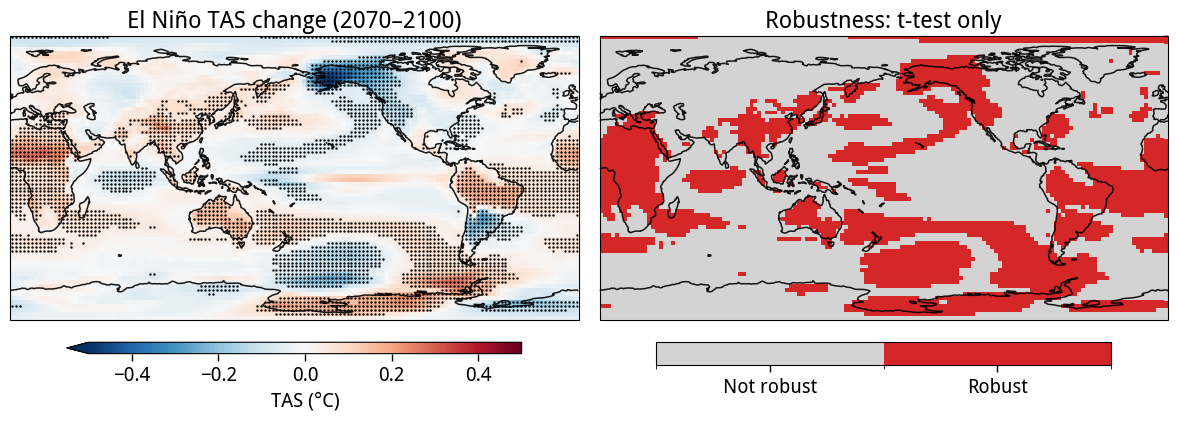

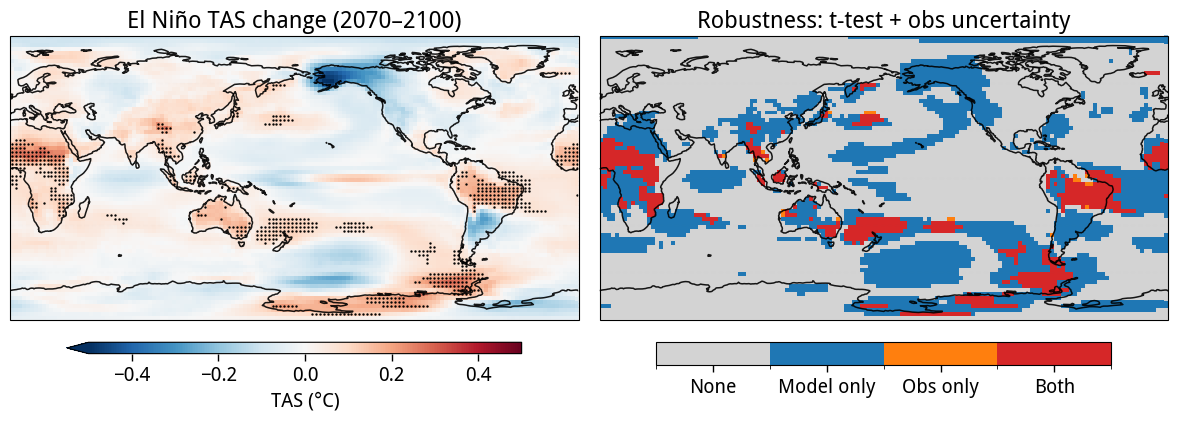

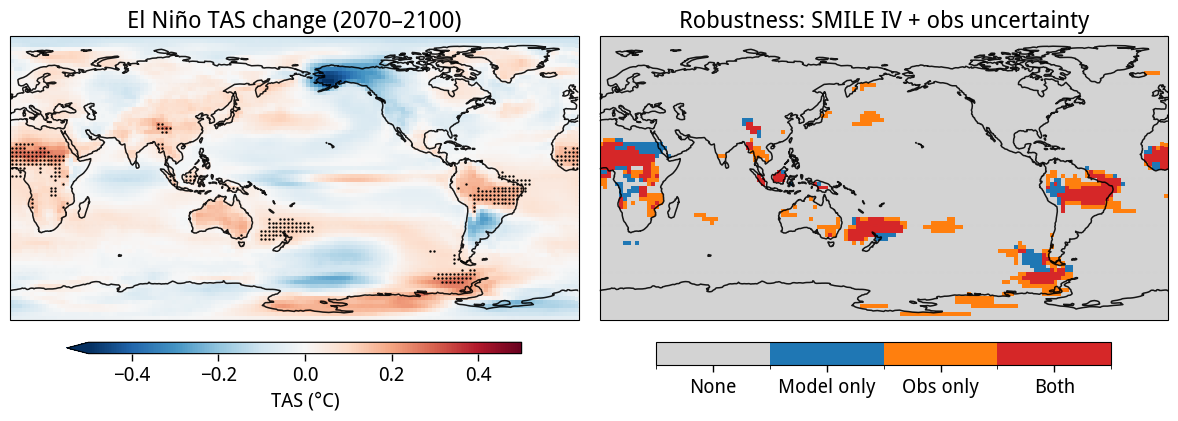

In [205]:
lon = tas_cmip6_regrid.lon.values
lat = tas_cmip6_regrid.lat.values

# --- EN TAS ---
# t-test only
plot_teleconnection_robustness(
    field        = signal_en_tas,
    lon=lon, lat=lat,
    pval_model   = pval_en_tas_ttest,
    use_pval     = True,
    cmap         = 'RdBu_r',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'TAS (°C)',
    title_main   = 'El Niño TAS change (2070–2100)',
    title_suffix = 'Robustness: t-test only'
)

# t-test + obs
plot_teleconnection_robustness(
    field        = signal_en_tas,
    lon=lon, lat=lat,
    pval_model   = pval_en_tas_ttest,
    snr_obs      = snr_en_tas_obs,
    use_pval     = True,
    cmap         = 'RdBu_r',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'TAS (°C)',
    title_main   = 'El Niño TAS change (2070–2100)',
    title_suffix = 'Robustness: t-test + obs uncertainty'
)

# SMILE IV + obs
plot_teleconnection_robustness(
    field        = signal_en_tas,
    lon=lon, lat=lat,
    snr_model    = snr_en_tas_iv,
    snr_obs      = snr_en_tas_obs,
    use_pval     = False,
    cmap         = 'RdBu_r',
    vmin=-0.5, vmax=0.5,
    cbar_label   = 'TAS (°C)',
    title_main   = 'El Niño TAS change (2070–2100)',
    title_suffix = 'Robustness: SMILE IV + obs uncertainty'
)


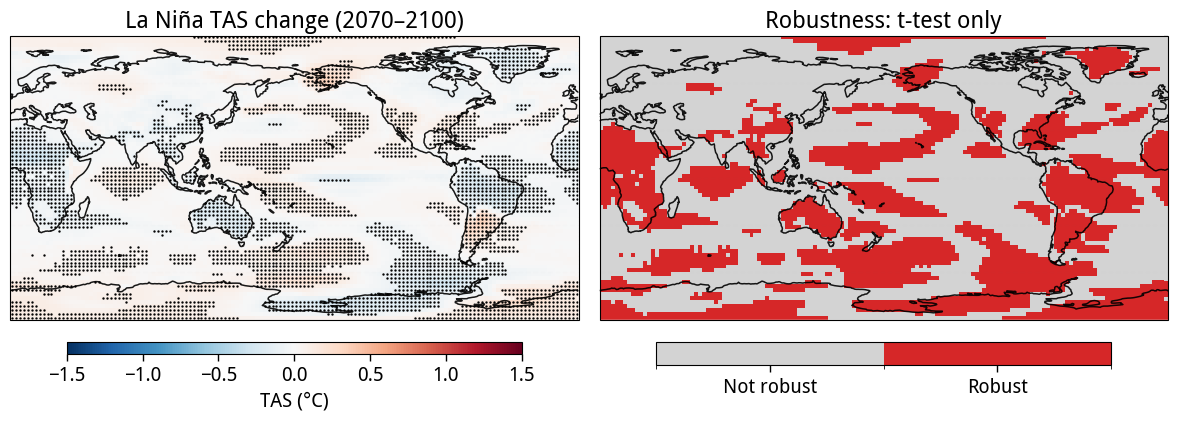

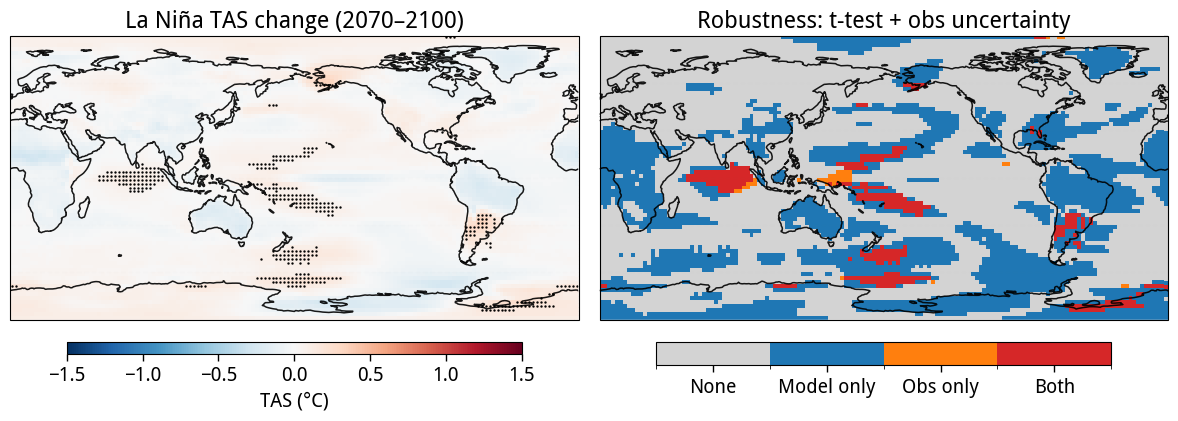

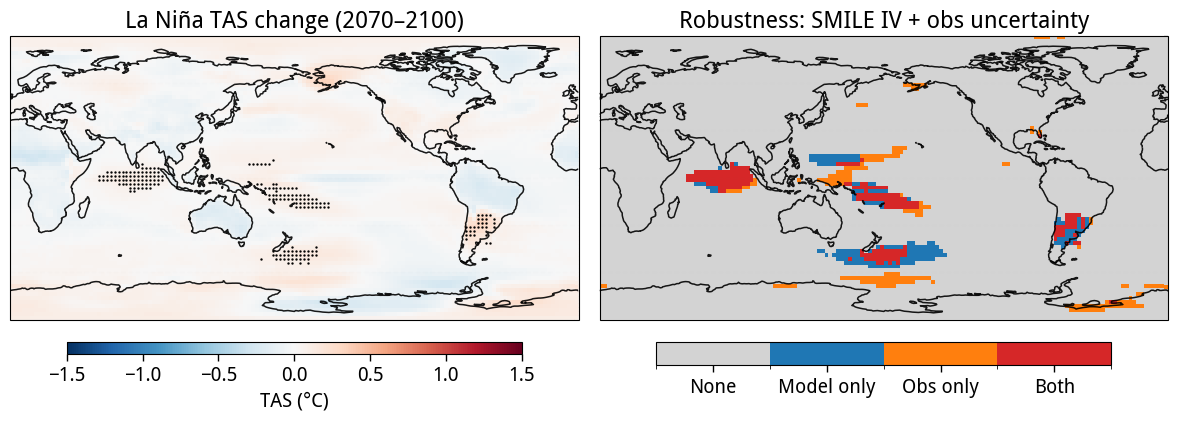

In [206]:
# --- LN TAS ---
plot_teleconnection_robustness(
    field        = signal_ln_tas,
    lon=lon, lat=lat,
    pval_model   = pval_ln_tas_ttest,
    use_pval     = True,
    cmap         = 'RdBu_r',
    vmin=-1.5, vmax=1.5,
    cbar_label   = 'TAS (°C)',
    title_main   = 'La Niña TAS change (2070–2100)',
    title_suffix = 'Robustness: t-test only'
)

plot_teleconnection_robustness(
    field        = signal_ln_tas,
    lon=lon, lat=lat,
    pval_model   = pval_ln_tas_ttest,
    snr_obs      = snr_ln_tas_obs,
    use_pval     = True,
    cmap         = 'RdBu_r',
    vmin=-1.5, vmax=1.5,
    cbar_label   = 'TAS (°C)',
    title_main   = 'La Niña TAS change (2070–2100)',
    title_suffix = 'Robustness: t-test + obs uncertainty'
)

plot_teleconnection_robustness(
    field        = signal_ln_tas,
    lon=lon, lat=lat,
    snr_model    = snr_ln_tas_iv,
    snr_obs      = snr_ln_tas_obs,
    use_pval     = False,
    cmap         = 'RdBu_r',
    vmin=-1.5, vmax=1.5,
    cbar_label   = 'TAS (°C)',
    title_main   = 'La Niña TAS change (2070–2100)',
    title_suffix = 'Robustness: SMILE IV + obs uncertainty'
)

In [218]:
snr_en_pr_obs

<xarray.DataArray (lat: 72, lon: 144)> Size: 41kB
array([[ 0.13282521,  0.14478259,  0.12647757, ...,  0.12703489,
         0.11657701,  0.12392535],
       [ 0.01126988,  0.04479686,  0.04155709, ..., -0.05112499,
        -0.04366819, -0.00815387],
       [-0.03967132,  0.0094673 ,  0.04950584, ..., -0.12541668,
        -0.08441355, -0.0610761 ],
       ...,
       [-0.20753752, -0.18084906, -0.17358942, ..., -0.26160192,
        -0.20191665, -0.17494743],
       [-0.30502906, -0.29665405, -0.3048842 , ..., -0.3861836 ,
        -0.34365073, -0.31205744],
       [-0.23738639, -0.2230325 , -0.21909639, ..., -0.28322312,
        -0.2732513 , -0.25609025]], dtype=float32)
Coordinates:
  * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * lat      (lat) float64 576B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75

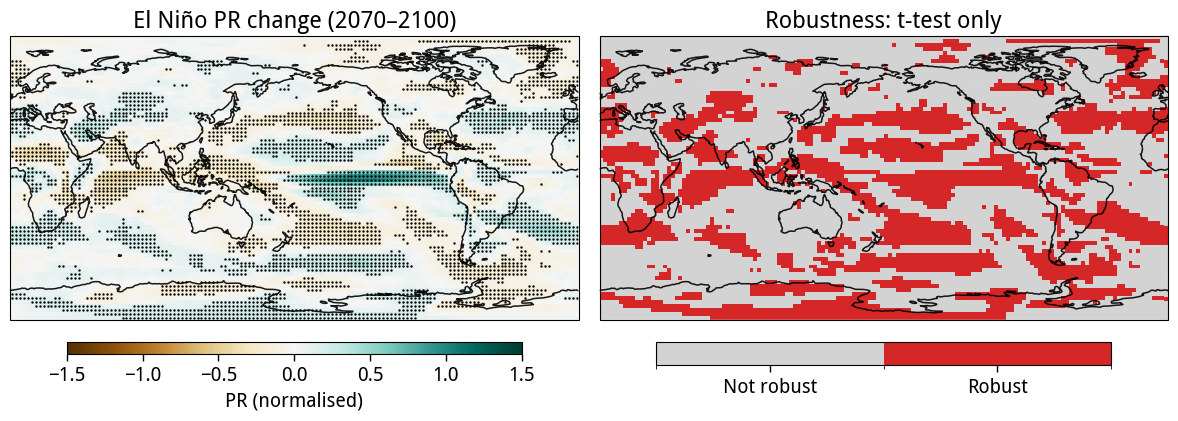

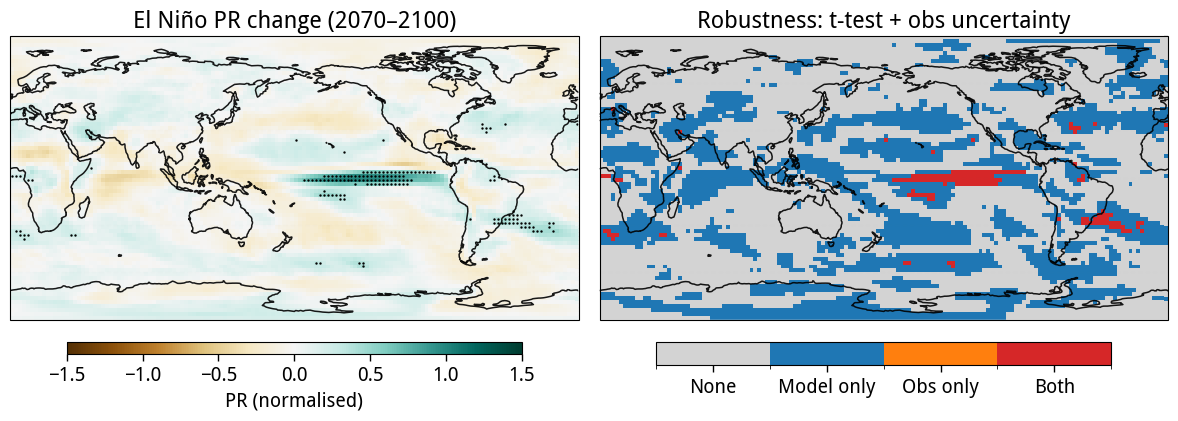

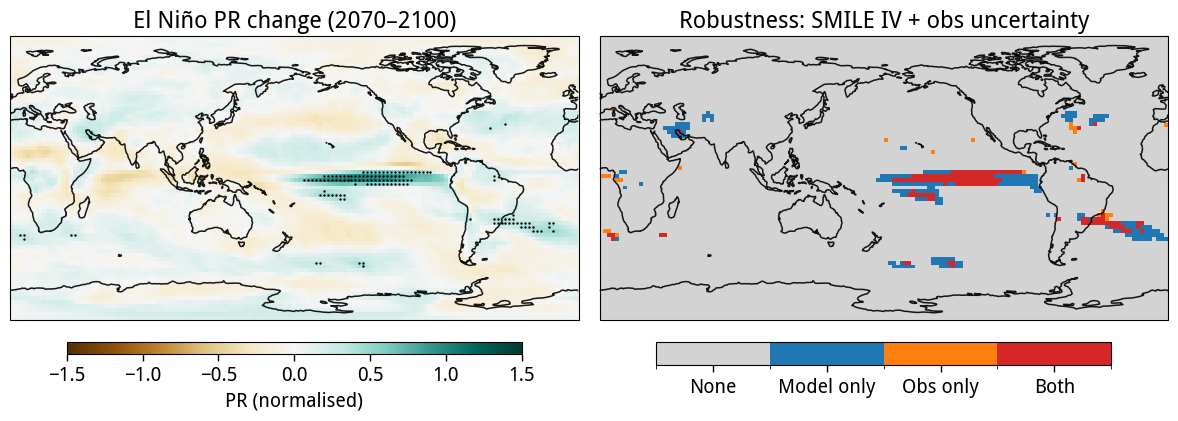

In [219]:

# --- EN PR ---
plot_teleconnection_robustness(
    field        = signal_en_pr,
    lon=lon, lat=lat,
    pval_model   = pval_en_pr_ttest,
    use_pval     = True,
    cmap         = 'BrBG',
    vmin=-1.5, vmax=1.5,
    cbar_label   = 'PR (normalised)',
    title_main   = 'El Niño PR change (2070–2100)',
    title_suffix = 'Robustness: t-test only'
)

plot_teleconnection_robustness(
    field        = signal_en_pr,
    lon=lon, lat=lat,
    pval_model   = pval_en_pr_ttest,
    snr_obs      = snr_en_pr_obs,
    use_pval     = True,
    cmap         = 'BrBG',
    vmin=-1.5, vmax=1.5,
    cbar_label   = 'PR (normalised)',
    title_main   = 'El Niño PR change (2070–2100)',
    title_suffix = 'Robustness: t-test + obs uncertainty'
)

plot_teleconnection_robustness(
    field        = signal_en_pr,
    lon=lon, lat=lat,
    snr_model    = snr_en_pr_iv,
    snr_obs      = snr_en_pr_obs,
    use_pval     = False,
    cmap         = 'BrBG',
    vmin=-1.5, vmax=1.5,
    cbar_label   = 'PR (normalised)',
    title_main   = 'El Niño PR change (2070–2100)',
    title_suffix = 'Robustness: SMILE IV + obs uncertainty'
)


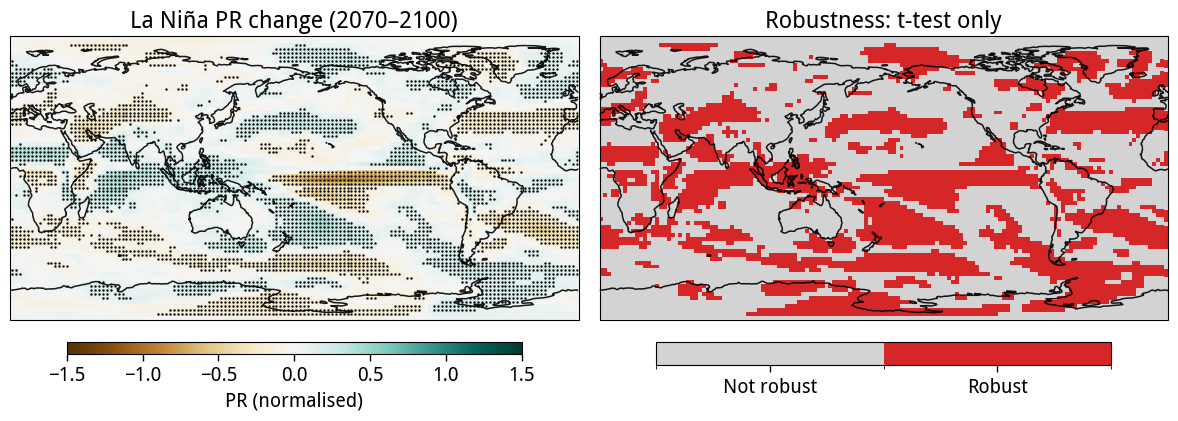

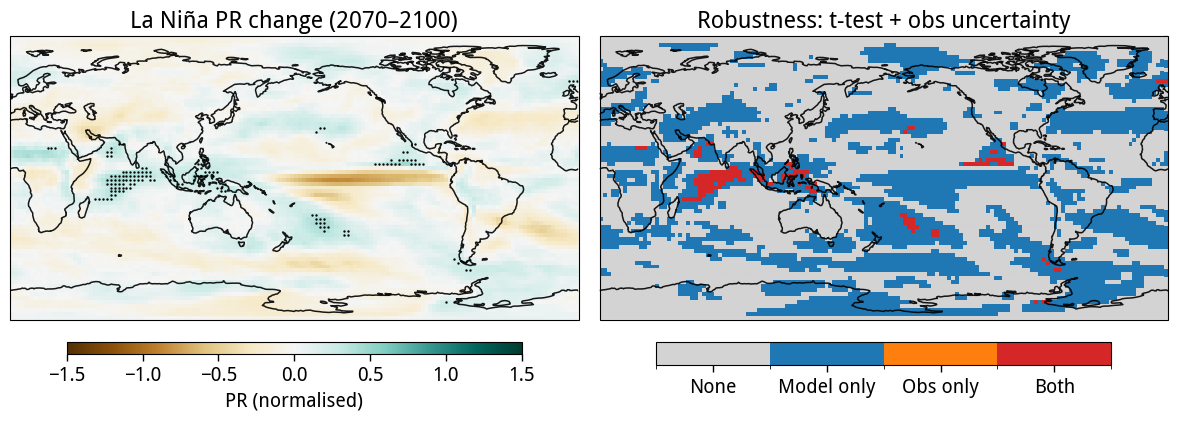

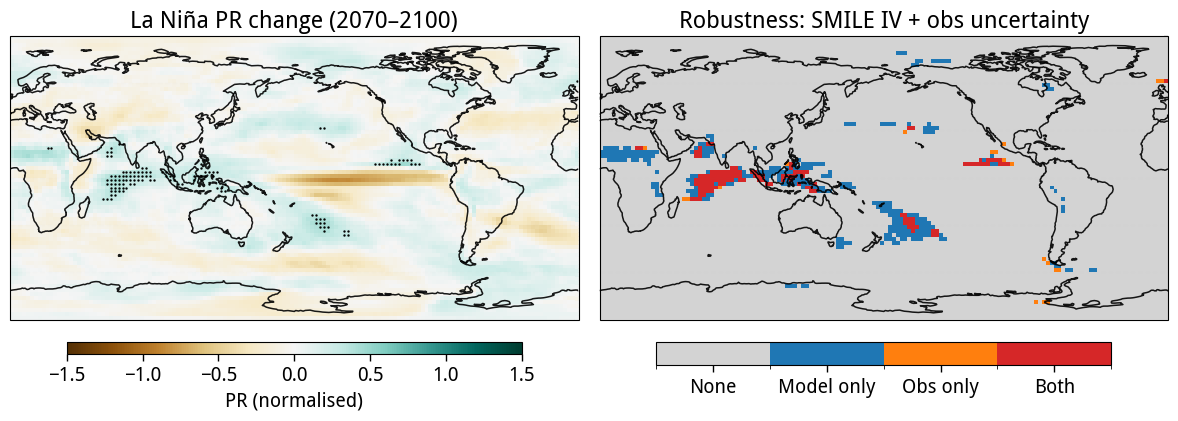

In [221]:
# --- LN PR ---
plot_teleconnection_robustness(
    field        = signal_ln_pr,
    lon=lon, lat=lat,
    pval_model   = pval_ln_pr_ttest,
    use_pval     = True,
    cmap         = 'BrBG',
    vmin=-1.5, vmax=1.5,
    cbar_label   = 'PR (normalised)',
    title_main   = 'La Niña PR change (2070–2100)',
    title_suffix = 'Robustness: t-test only'
)

plot_teleconnection_robustness(
    field        = signal_ln_pr,
    lon=lon, lat=lat,
    pval_model   = pval_ln_pr_ttest,
    snr_obs      = snr_ln_pr_obs,
    use_pval     = True,
    cmap         = 'BrBG',
    vmin=-1.5, vmax=1.5,
    cbar_label   = 'PR (normalised)',
    title_main   = 'La Niña PR change (2070–2100)',
    title_suffix = 'Robustness: t-test + obs uncertainty'
)

plot_teleconnection_robustness(
    field        = signal_ln_pr,
    lon=lon, lat=lat,
    snr_model    = snr_ln_pr_iv,
    snr_obs      = snr_ln_pr_obs,
    use_pval     = False,
    cmap         = 'BrBG',
    vmin=-1.5, vmax=1.5,
    cbar_label   = 'PR (normalised)',
    title_main   = 'La Niña PR change (2070–2100)',
    title_suffix = 'Robustness: SMILE IV + obs uncertainty'
)

In [223]:
def plot_enso_agreement(mask_en, mask_ln, lon, lat, title=''):
    
    # 0: neither, 1: EN only, 2: LN only, 3: both
    cat = mask_en.astype(int) + 2 * mask_ln.astype(int)

    cmap_cat = mcolors.ListedColormap([
        'lightgrey',    # neither
        'tab:blue',     # EN only
        'tab:orange',   # LN only
        'tab:red',      # both
    ])
    bounds = [0, 1, 2, 3, 4]
    ticks  = [0.5, 1.5, 2.5, 3.5]
    labels = ['Neither', 'EN only', 'LN only', 'Both']
    norm   = mcolors.BoundaryNorm(bounds, cmap_cat.N)

    xx, yy = np.meshgrid(lon, lat)

    fig, ax = plt.subplots(
        subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=180)),
        figsize=(10, 4)
    )
    im = ax.pcolormesh(xx, yy, cat, cmap=cmap_cat, norm=norm,
                       transform=ccrs.PlateCarree())

    cbar = plt.colorbar(im, ax=ax, orientation='horizontal',
                        pad=0.05, fraction=0.046, aspect=30)
    cbar.set_ticks(ticks)
    cbar.set_ticklabels(labels)

    ax.set_title(title)
    plot_background(ax)
    plt.tight_layout()
    # return fig

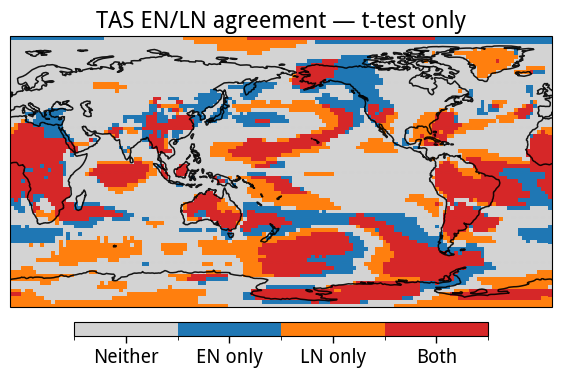

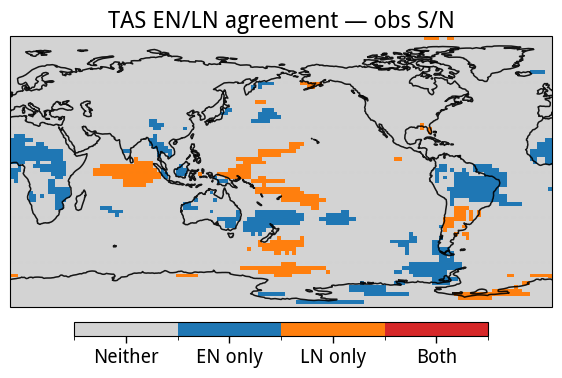

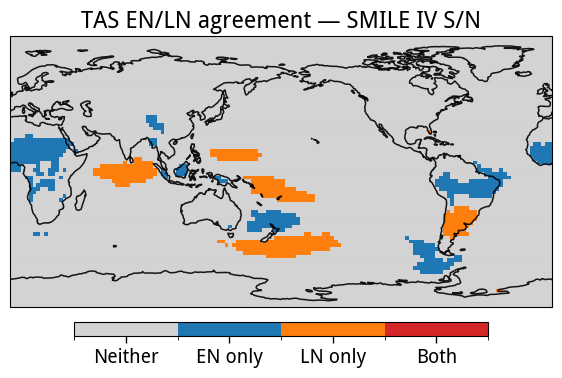

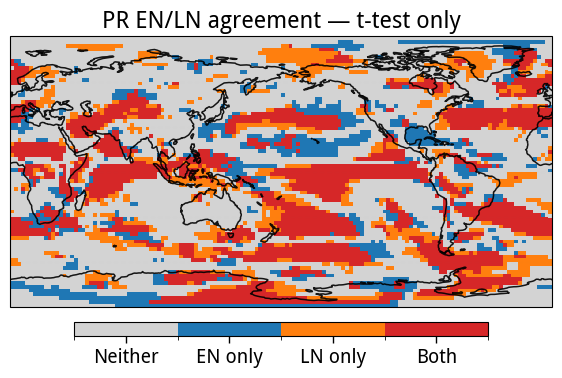

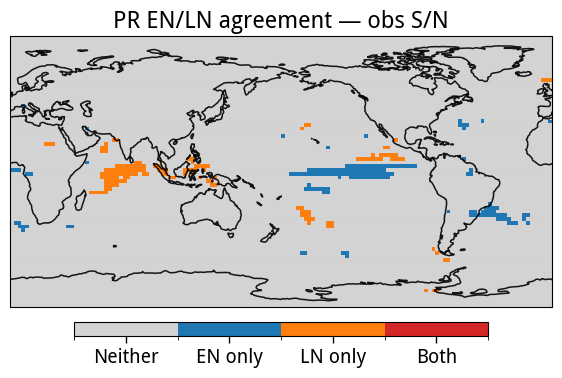

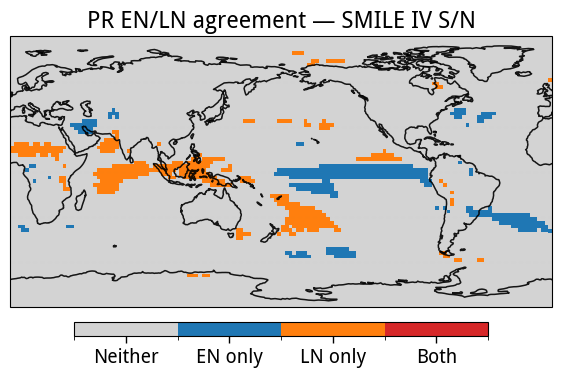

In [224]:
lon = tas_smile['ACCESS-ESM1-5'].lon.values
lat = tas_smile['ACCESS-ESM1-5'].lat.values

# --- TAS ---
# t-test only
plot_enso_agreement(mask_en_tas_ttest, mask_ln_tas_ttest, lon, lat,
                    title='TAS EN/LN agreement — t-test only')

# obs S/N
plot_enso_agreement(mask_en_tas_obs, mask_ln_tas_obs, lon, lat,
                    title='TAS EN/LN agreement — obs S/N')

# SMILE IV
plot_enso_agreement(mask_en_tas_iv, mask_ln_tas_iv, lon, lat,
                    title='TAS EN/LN agreement — SMILE IV S/N')

# --- PR ---
# t-test only
plot_enso_agreement(mask_en_pr_ttest, mask_ln_pr_ttest, lon, lat,
                    title='PR EN/LN agreement — t-test only')

# obs S/N
plot_enso_agreement(mask_en_pr_obs, mask_ln_pr_obs, lon, lat,
                    title='PR EN/LN agreement — obs S/N')

# SMILE IV
plot_enso_agreement(mask_en_pr_iv, mask_ln_pr_iv, lon, lat,
                    title='PR EN/LN agreement — SMILE IV S/N')